# MentalDistress — Step 4: Flat Transformer Baselines — MentalRoBERTa 10-Seed Principal Run

One execution trains the same MentalRoBERTa configuration sequentially for the ten fixed principal seeds. 
All seeds use the same locked train/validation data, pinned model revision, 512-token limit, optimizer/training budget, 
checkpoint-selection rule, evaluation logic, integrity checks, and artifact format as the original single-seed notebook. 
Each seed receives its own run directory plus `*_MODELS.zip` and `*_ARTIFACTS.zip`. 
`RUN_MODE="smoke"` preserves the original same-seed reproducibility check for each seed. 
`RUN_MODE="full"` trains on the complete locked training split and evaluates only the locked validation split. 
The test split is not opened, read, loaded, inferred on, or evaluated.


In [1]:
from kaggle_secrets import UserSecretsClient
user_secrets = UserSecretsClient()
secret_value_0 = user_secrets.get_secret("hf_model_read")

In [2]:
# CONFIG
import os
from pathlib import Path
# MODEL_REGISTRY = {
#     "bert": "google-bert/bert-base-uncased",
#     "roberta": "FacebookAI/roberta-base",
#     "mentalroberta": "mental/mental-roberta-base",
#     "electra": "google/electra-base-discriminator",
# }
MODEL_KEY = "mentalroberta"
RUN_MODE = "full"                 # "full" or "smoke"
DEVICE = "cuda"                   # "cuda" or "cpu"
TRAIN_PATH = Path("/kaggle/input/datasets/sayemahmedshayeed/mentaldistress-locked-dataset/MentalDistress_train_LOCKED.csv")
VALIDATION_PATH = Path("/kaggle/input/datasets/sayemahmedshayeed/mentaldistress-locked-dataset/MentalDistress_validation_LOCKED.csv")
OUTPUT_ROOT = None                 # None -> /kaggle/working/mental_distress_step4
MODEL_SOURCE_OVERRIDE = None       # local model directory, otherwise registry source is used
# Pinned to the exact MentalRoBERTa revision used by the existing seed 42/123/3407 runs.
MODEL_REVISION = "610e9d35d8f2550d713579077242d5e523209cea"
HF_TOKEN_ENV = "hf_model_read"

# Fixed principal seed set from the pre-experiment reviewer-resilient protocol.
SEEDS = [13, 42, 77, 123, 211, 340, 512, 1024, 2026, 3407]
SEED = SEEDS[0]                    # bootstrap seed for notebook initialization only
MAX_LENGTH = 512
TRAIN_BATCH_SIZE = 8
EVAL_BATCH_SIZE = 16
GRAD_ACCUM_STEPS = 4
EPOCHS = 8
PATIENCE = 3
LEARNING_RATE = 2e-5
WEIGHT_DECAY = 0.01
WARMUP_RATIO = 0.10
MAX_GRAD_NORM = 1.0

SMOKE_TRAIN_PER_CLASS = 8
SMOKE_VAL_PER_CLASS = 4
SMOKE_EPOCHS = 1
SMOKE_REPRODUCIBILITY_CHECK = True
REPRO_ATOL = 1e-5
REPRO_RTOL = 1e-6

OVERWRITE_RUN = True
STRICT_DETERMINISM = True

MODEL_REGISTRY = {
    "bert": "google-bert/bert-base-uncased",
    "roberta": "FacebookAI/roberta-base",
    "mentalroberta": "mental/mental-roberta-base",
    "electra": "google/electra-base-discriminator",
}

LABELS = ["Suicidal", "Depressed", "Anxious", "Frustrated", "Others"]
LABEL2ID = {label: i for i, label in enumerate(LABELS)}
ID2LABEL = {i: label for label, i in LABEL2ID.items()}

os.environ["PYTHONHASHSEED"] = str(SEED)
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["TRANSFORMERS_VERBOSITY"] = "error"
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"

assert MODEL_KEY in MODEL_REGISTRY
assert RUN_MODE in {"full", "smoke"}
assert DEVICE in {"cuda", "cpu"}
assert len(SEEDS) == 10 and len(set(SEEDS)) == 10
assert MAX_LENGTH > 0 and TRAIN_BATCH_SIZE > 0 and EVAL_BATCH_SIZE > 0
assert GRAD_ACCUM_STEPS > 0 and EPOCHS > 0 and PATIENCE > 0


In [3]:
import sys
import json
import math
import random
import hashlib
import shutil
import platform
import subprocess
import zipfile
from pathlib import Path

try:
    import numpy as np
    import pandas as pd
    import sklearn
    import torch
    import transformers
    transformers.logging.set_verbosity_error()
    import tokenizers
    import huggingface_hub
    import matplotlib.pyplot as plt
    from IPython.display import display
    from sklearn.metrics import (
        accuracy_score,
        classification_report,
        confusion_matrix,
        f1_score,
        matthews_corrcoef,
        precision_score,
        recall_score,
    )
    from torch.utils.data import Dataset, DataLoader
    from transformers import (
        AutoConfig,
        AutoModelForSequenceClassification,
        AutoTokenizer,
        DataCollatorWithPadding,
        get_linear_schedule_with_warmup,
    )
    from huggingface_hub import HfApi
except Exception as exc:
    raise RuntimeError(
        'Required packages are missing. Use a controlled environment with torch, transformers, '
        'tokenizers, huggingface_hub, scikit-learn, pandas, numpy, matplotlib, sentencepiece and safetensors.'
    ) from exc


def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
    if hasattr(torch.backends, "cuda") and hasattr(torch.backends.cuda, "matmul"):
        torch.backends.cuda.matmul.allow_tf32 = False
    if hasattr(torch.backends, "cudnn"):
        torch.backends.cudnn.allow_tf32 = False
    if STRICT_DETERMINISM:
        torch.use_deterministic_algorithms(True, warn_only=False)
    if hasattr(torch, "set_float32_matmul_precision"):
        torch.set_float32_matmul_precision("highest")


seed_everything(SEED)

if DEVICE == "cuda" and not torch.cuda.is_available():
    raise RuntimeError('DEVICE="cuda" but CUDA is unavailable. Use a GPU runtime or set DEVICE="cpu".')
device = torch.device(DEVICE)

environment = {
    "python": sys.version.split()[0],
    "platform": platform.platform(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scikit_learn": sklearn.__version__,
    "torch": torch.__version__,
    "transformers": transformers.__version__,
    "tokenizers": tokenizers.__version__,
    "huggingface_hub": huggingface_hub.__version__,
    "cuda_runtime": torch.version.cuda,
    "cudnn": torch.backends.cudnn.version() if torch.backends.cudnn.is_available() else None,
    "device": str(device),
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
    "deterministic_algorithms": torch.are_deterministic_algorithms_enabled(),
}
display(pd.DataFrame([environment]))


HF_TOKEN = None
if MODEL_KEY == "mentalroberta":
    try:
        from kaggle_secrets import UserSecretsClient
        from huggingface_hub import login

        user_secrets = UserSecretsClient()
        HF_TOKEN = user_secrets.get_secret("hf_model_read")
        if not HF_TOKEN:
            raise RuntimeError("Kaggle secret 'hf_model_read' is empty.")
        login(token=HF_TOKEN, add_to_git_credential=False)
    except Exception as exc:
        raise RuntimeError(
            "MentalRoBERTa requires Hugging Face authentication. "
            "Add a Kaggle secret named 'hf_model_read' containing a Hugging Face read token."
        ) from exc



,python,platform,numpy,pandas,scikit_learn,torch,transformers,tokenizers,huggingface_hub,cuda_runtime,cudnn,device,gpu,deterministic_algorithms
0,3.12.13,Linux-6.12.90+-x86_64-with-glibc2.35,2.0.2,2.3.3,1.6.1,2.10.0+cu128,5.0.0,0.22.2,1.11.0,12.8,91002,cuda,Tesla T4,True


In [4]:
def sha256_file(path: Path, chunk_size: int = 1024 * 1024) -> str:
    h = hashlib.sha256()
    with path.open("rb") as f:
        while True:
            chunk = f.read(chunk_size)
            if not chunk:
                break
            h.update(chunk)
    return h.hexdigest()


def sha256_tree(root: Path) -> str:
    h = hashlib.sha256()
    for p in sorted(x for x in root.rglob("*") if x.is_file()):
        h.update(p.relative_to(root).as_posix().encode("utf-8"))
        h.update(sha256_file(p).encode("ascii"))
    return h.hexdigest()


if not TRAIN_PATH.is_file():
    raise FileNotFoundError(f"Training CSV not found: {TRAIN_PATH}")
if not VALIDATION_PATH.is_file():
    raise FileNotFoundError(f"Validation CSV not found: {VALIDATION_PATH}")

frames = {
    "train": pd.read_csv(TRAIN_PATH),
    "validation": pd.read_csv(VALIDATION_PATH),
}

expected_counts = {"train": 6954, "validation": 1490}
expected_classes = {
    "train": {"Others": 1779, "Suicidal": 1492, "Anxious": 1370, "Frustrated": 1292, "Depressed": 1021},
    "validation": {"Others": 381, "Suicidal": 319, "Anxious": 294, "Frustrated": 277, "Depressed": 219},
}
required_columns = {"original_row", "text", "label"}

for name, df in frames.items():
    assert len(df) == expected_counts[name], (name, len(df), expected_counts[name])
    assert required_columns.issubset(df.columns), (name, df.columns.tolist())
    assert df["original_row"].is_unique, f"Duplicate original_row in {name}"
    assert df["text"].notna().all() and df["text"].astype(str).str.strip().ne("").all(), f"Invalid text in {name}"
    assert set(df["label"].unique()) <= set(LABELS), f"Invalid label in {name}"
    got = df["label"].value_counts().to_dict()
    assert got == expected_classes[name], (name, got, expected_classes[name])

train_ids = set(frames["train"]["original_row"])
val_ids = set(frames["validation"]["original_row"])
assert train_ids.isdisjoint(val_ids), "Train/validation row overlap detected."

integrity = {
    "rows": expected_counts,
    "sha256": {
        "train": sha256_file(TRAIN_PATH),
        "validation": sha256_file(VALIDATION_PATH),
    },
    "class_counts": expected_classes,
    "train_validation_disjoint": True,
    "test_accessed": False,
}

display(pd.DataFrame([
    {"split": "train", "rows": len(frames["train"]), "path": str(TRAIN_PATH), "sha256": integrity["sha256"]["train"]},
    {"split": "validation", "rows": len(frames["validation"]), "path": str(VALIDATION_PATH), "sha256": integrity["sha256"]["validation"]},
]))


,split,rows,path,sha256
0,train,6954,/kaggle/input/datasets/sayemahmedshayeed/menta...,1bac0d2f4e0f4d3da940b08a21bd3c6e18b1d958c57cb2...
1,validation,1490,/kaggle/input/datasets/sayemahmedshayeed/menta...,88835cd714b02efbd230536c7de3f455e807051a23a178...


In [5]:
def stratified_smoke_sample(df: pd.DataFrame, per_class: int, seed: int) -> pd.DataFrame:
    parts = []
    for label in LABELS:
        part = df[df["label"] == label]
        n = min(per_class, len(part))
        parts.append(part.sample(n=n, random_state=seed).sort_values("original_row"))
    return pd.concat(parts, ignore_index=True).sort_values("original_row").reset_index(drop=True)


model_source = str(Path(MODEL_SOURCE_OVERRIDE).resolve()) if MODEL_SOURCE_OVERRIDE else MODEL_REGISTRY[MODEL_KEY]
hf_token = os.environ.get(HF_TOKEN_ENV) or None
resolved_revision = MODEL_REVISION

if MODEL_SOURCE_OVERRIDE is None and resolved_revision is None:
    try:
        resolved_revision = HfApi().model_info(model_source, token=hf_token).sha
    except Exception as exc:
        raise RuntimeError(
            "Could not resolve a pinned Hugging Face commit. Enable internet/authentication or set MODEL_REVISION explicitly."
        ) from exc

source_kwargs = {}
if MODEL_SOURCE_OVERRIDE is None:
    source_kwargs["revision"] = resolved_revision
    if hf_token:
        source_kwargs["token"] = hf_token

seed_everything(SEED)
tokenizer = AutoTokenizer.from_pretrained(model_source, use_fast=True, **source_kwargs)
base_config = AutoConfig.from_pretrained(
    model_source,
    num_labels=len(LABELS),
    label2id=LABEL2ID,
    id2label=ID2LABEL,
    **source_kwargs,
)
base_config._attn_implementation = "eager"

resolved_model = {
    "model_key": MODEL_KEY,
    "hf_authenticated": bool(HF_TOKEN is not None),
    "source": model_source,
    "revision": resolved_revision,
    "local_source_sha256": sha256_tree(Path(model_source)) if MODEL_SOURCE_OVERRIDE else None,
    "attention_implementation": getattr(base_config, "_attn_implementation", None),
}

if OUTPUT_ROOT is None:
    root = Path("/kaggle/working/mental_distress_step4") if Path("/kaggle/working").exists() else Path("/mnt/data/mental_distress_step4")
else:
    root = Path(OUTPUT_ROOT)
root.mkdir(parents=True, exist_ok=True)

print(json.dumps({
    "model": resolved_model,
    "principal_seeds": SEEDS,
    "train_rows": len(frames["train"]),
    "validation_rows": len(frames["validation"]),
    "max_length": MAX_LENGTH,
    "test_accessed": False,
}, indent=2))


config.json:   0%|          | 0.00/682 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/327 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

{
  "model": {
    "model_key": "mentalroberta",
    "hf_authenticated": true,
    "source": "mental/mental-roberta-base",
    "revision": "610e9d35d8f2550d713579077242d5e523209cea",
    "local_source_sha256": null,
    "attention_implementation": "eager"
  },
  "principal_seeds": [
    13,
    42,
    77,
    123,
    211,
    340,
    512,
    1024,
    2026,
    3407
  ],
  "train_rows": 6954,
  "validation_rows": 1490,
  "max_length": 512,
  "test_accessed": false
}


In [6]:
class EncodedDataset(Dataset):
    def __init__(self, df: pd.DataFrame, tokenizer, max_length: int):
        self.labels = df["label_id"].tolist()
        self.encodings = tokenizer(
            df["text"].astype(str).tolist(),
            truncation=True,
            max_length=max_length,
            padding=False,
        )

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        item = {k: v[idx] for k, v in self.encodings.items()}
        item["labels"] = self.labels[idx]
        return item


collator = DataCollatorWithPadding(tokenizer=tokenizer, padding="longest", return_tensors="pt")


def make_train_loader(train_dataset, seed: int):
    generator = torch.Generator()
    generator.manual_seed(seed)
    return DataLoader(
        train_dataset,
        batch_size=TRAIN_BATCH_SIZE,
        shuffle=True,
        generator=generator,
        collate_fn=collator,
        num_workers=0,
        pin_memory=(device.type == "cuda"),
        drop_last=False,
    )


def make_val_loader(val_dataset):
    return DataLoader(
        val_dataset,
        batch_size=EVAL_BATCH_SIZE,
        shuffle=False,
        collate_fn=collator,
        num_workers=0,
        pin_memory=(device.type == "cuda"),
        drop_last=False,
    )


def new_model(seed: int):
    seed_everything(seed)
    cfg = AutoConfig.from_pretrained(
        model_source,
        num_labels=len(LABELS),
        label2id=LABEL2ID,
        id2label=ID2LABEL,
        **source_kwargs,
    )
    cfg._attn_implementation = "eager"
    model = AutoModelForSequenceClassification.from_pretrained(model_source, config=cfg, **source_kwargs)
    return model.to(device)


def metric_bundle(y_true, y_pred):
    return {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "macro_precision": float(precision_score(y_true, y_pred, average="macro", zero_division=0)),
        "macro_recall": float(recall_score(y_true, y_pred, average="macro", zero_division=0)),
        "macro_f1": float(f1_score(y_true, y_pred, average="macro", zero_division=0)),
        "weighted_f1": float(f1_score(y_true, y_pred, average="weighted", zero_division=0)),
        "mcc": float(matthews_corrcoef(y_true, y_pred)),
    }


def evaluate(model, loader):
    model.eval()
    total_loss = 0.0
    total_n = 0
    logits_parts, labels_parts = [], []
    with torch.inference_mode():
        for batch in loader:
            labels = batch["labels"].to(device, non_blocking=True)
            inputs = {k: v.to(device, non_blocking=True) for k, v in batch.items() if k != "labels"}
            outputs = model(**inputs, labels=labels)
            bs = labels.size(0)
            total_loss += float(outputs.loss.detach().cpu()) * bs
            total_n += bs
            logits_parts.append(outputs.logits.detach().cpu())
            labels_parts.append(labels.detach().cpu())
    logits = torch.cat(logits_parts, dim=0).numpy()
    y_true = torch.cat(labels_parts, dim=0).numpy()
    probs = torch.softmax(torch.from_numpy(logits), dim=1).numpy()
    y_pred = probs.argmax(axis=1)
    metrics = metric_bundle(y_true, y_pred)
    metrics["loss"] = total_loss / total_n
    return {"metrics": metrics, "logits": logits, "probs": probs, "y_true": y_true, "y_pred": y_pred}


In [7]:
def save_best_checkpoint(model, checkpoint_dir: Path, meta: dict):
    checkpoint_dir.mkdir(parents=True, exist_ok=True)
    model.save_pretrained(checkpoint_dir, safe_serialization=True)
    tokenizer.save_pretrained(checkpoint_dir)
    with (checkpoint_dir / "checkpoint_meta.json").open("w", encoding="utf-8") as f:
        json.dump(meta, f, indent=2, sort_keys=True)


def train_once(target_dir: Path, seed: int, epochs: int, train_dataset, val_dataset, run_id: str):
    if target_dir.exists():
        shutil.rmtree(target_dir)
    target_dir.mkdir(parents=True, exist_ok=True)

    model = new_model(seed)
    train_loader = make_train_loader(train_dataset, seed)
    val_loader = make_val_loader(val_dataset)

    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    optimizer_steps_per_epoch = math.ceil(len(train_loader) / GRAD_ACCUM_STEPS)
    total_optimizer_steps = optimizer_steps_per_epoch * epochs
    warmup_steps = int(round(total_optimizer_steps * WARMUP_RATIO))
    scheduler = get_linear_schedule_with_warmup(
        optimizer,
        num_warmup_steps=warmup_steps,
        num_training_steps=total_optimizer_steps,
    )

    best_f1 = -1.0
    best_loss = float("inf")
    best_epoch = None
    no_improve = 0
    history = []
    checkpoint_dir = target_dir / "best_model"

    for epoch in range(1, epochs + 1):
        model.train()
        optimizer.zero_grad(set_to_none=True)
        train_loss_sum = 0.0
        train_n = 0
        train_preds, train_labels = [], []

        for step, batch in enumerate(train_loader):
            labels = batch["labels"].to(device, non_blocking=True)
            inputs = {k: v.to(device, non_blocking=True) for k, v in batch.items() if k != "labels"}
            outputs = model(**inputs, labels=labels)
            raw_loss = outputs.loss
            (raw_loss / GRAD_ACCUM_STEPS).backward()

            bs = labels.size(0)
            train_loss_sum += float(raw_loss.detach().cpu()) * bs
            train_n += bs
            train_preds.extend(outputs.logits.detach().argmax(dim=1).cpu().tolist())
            train_labels.extend(labels.detach().cpu().tolist())

            do_step = ((step + 1) % GRAD_ACCUM_STEPS == 0) or (step + 1 == len(train_loader))
            if do_step:
                torch.nn.utils.clip_grad_norm_(model.parameters(), MAX_GRAD_NORM)
                optimizer.step()
                scheduler.step()
                optimizer.zero_grad(set_to_none=True)

        val_out = evaluate(model, val_loader)
        train_metrics = metric_bundle(np.array(train_labels), np.array(train_preds))
        row = {
            "epoch": epoch,
            "train_loss": train_loss_sum / train_n,
            "train_macro_f1": train_metrics["macro_f1"],
            "val_loss": val_out["metrics"]["loss"],
            "val_macro_f1": val_out["metrics"]["macro_f1"],
            "val_accuracy": val_out["metrics"]["accuracy"],
            "learning_rate": float(scheduler.get_last_lr()[0]),
        }
        history.append(row)
        print(json.dumps({"seed": seed, **row}, sort_keys=True))

        improved = (
            row["val_macro_f1"] > best_f1 + 1e-12
            or (abs(row["val_macro_f1"] - best_f1) <= 1e-12 and row["val_loss"] < best_loss - 1e-12)
        )
        if improved:
            best_f1 = row["val_macro_f1"]
            best_loss = row["val_loss"]
            best_epoch = epoch
            no_improve = 0
            save_best_checkpoint(
                model,
                checkpoint_dir,
                {
                    "best_epoch": best_epoch,
                    "validation_macro_f1": best_f1,
                    "validation_loss": best_loss,
                    "seed": seed,
                    "run_id": run_id,
                    "test_accessed": False,
                },
            )
        else:
            no_improve += 1
            if RUN_MODE == "full" and no_improve >= PATIENCE:
                break

    del model
    if device.type == "cuda":
        torch.cuda.empty_cache()

    reload_model = AutoModelForSequenceClassification.from_pretrained(checkpoint_dir).to(device)
    reloaded = evaluate(reload_model, make_val_loader(val_dataset))
    del reload_model
    if device.type == "cuda":
        torch.cuda.empty_cache()

    return {
        "history": history,
        "best_epoch": best_epoch,
        "checkpoint_dir": checkpoint_dir,
        "validation": reloaded,
    }


In [8]:
def write_hash_manifest(root: Path, output_file: Path):
    rows = []
    for p in sorted(x for x in root.rglob("*") if x.is_file() and x != output_file):
        rows.append({"path": p.relative_to(root).as_posix(), "sha256": sha256_file(p), "bytes": p.stat().st_size})
    pd.DataFrame(rows).to_csv(output_file, index=False)


def deterministic_zip(source_dir: Path, zip_path: Path, prefix: str):
    fixed_time = (2020, 1, 1, 0, 0, 0)
    with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED, compresslevel=9) as zf:
        for p in sorted(x for x in source_dir.rglob("*") if x.is_file()):
            rel = Path(prefix) / p.relative_to(source_dir)
            info = zipfile.ZipInfo(rel.as_posix(), fixed_time)
            info.compress_type = zipfile.ZIP_DEFLATED
            info.external_attr = 0o644 << 16
            zf.writestr(info, p.read_bytes())


def run_seed(seed: int):
    seed_everything(seed)

    train_df = frames["train"].copy()
    val_df = frames["validation"].copy()
    if RUN_MODE == "smoke":
        train_df = stratified_smoke_sample(train_df, SMOKE_TRAIN_PER_CLASS, seed)
        val_df = stratified_smoke_sample(val_df, SMOKE_VAL_PER_CLASS, seed)

    train_df["label_id"] = train_df["label"].map(LABEL2ID).astype(int)
    val_df["label_id"] = val_df["label"].map(LABEL2ID).astype(int)
    train_dataset = EncodedDataset(train_df, tokenizer, MAX_LENGTH)
    val_dataset = EncodedDataset(val_df, tokenizer, MAX_LENGTH)

    run_signature_payload = {
        "model": resolved_model,
        "seed": seed,
        "max_length": MAX_LENGTH,
        "train_batch_size": TRAIN_BATCH_SIZE,
        "eval_batch_size": EVAL_BATCH_SIZE,
        "grad_accum_steps": GRAD_ACCUM_STEPS,
        "epochs": EPOCHS if RUN_MODE == "full" else SMOKE_EPOCHS,
        "patience": PATIENCE,
        "learning_rate": LEARNING_RATE,
        "weight_decay": WEIGHT_DECAY,
        "warmup_ratio": WARMUP_RATIO,
        "max_grad_norm": MAX_GRAD_NORM,
        "run_mode": RUN_MODE,
        "data_sha256": integrity["sha256"],
    }
    run_signature = hashlib.sha256(json.dumps(run_signature_payload, sort_keys=True).encode("utf-8")).hexdigest()[:12]
    run_id = f"{MODEL_KEY}_{RUN_MODE}_seed{seed}_len{MAX_LENGTH}_{run_signature}"
    run_dir = root / run_id
    if run_dir.exists() and OVERWRITE_RUN:
        shutil.rmtree(run_dir)
    run_dir.mkdir(parents=True, exist_ok=True)

    print("=" * 96)
    print(json.dumps({
        "starting_seed": seed,
        "run_id": run_id,
        **resolved_model,
        "train_rows": len(train_df),
        "validation_rows": len(val_df),
        "test_accessed": False,
    }, indent=2))

    epochs_to_run = EPOCHS if RUN_MODE == "full" else SMOKE_EPOCHS
    primary_dir = run_dir / "primary"
    primary = train_once(primary_dir, seed, epochs_to_run, train_dataset, val_dataset, run_id)

    reproducibility_check = {"performed": False, "passed": None}
    if RUN_MODE == "smoke" and SMOKE_REPRODUCIBILITY_CHECK:
        second_dir = run_dir / "repro_second"
        second = train_once(second_dir, seed, epochs_to_run, train_dataset, val_dataset, run_id)

        primary_logits = primary["validation"]["logits"]
        second_logits = second["validation"]["logits"]
        same_predictions = np.array_equal(primary["validation"]["y_pred"], second["validation"]["y_pred"])

        metric_keys = ["accuracy", "macro_precision", "macro_recall", "macro_f1", "weighted_f1", "mcc"]
        same_discrete_metrics = all(
            primary["validation"]["metrics"][key] == second["validation"]["metrics"][key]
            for key in metric_keys
        )

        logits_close = np.allclose(primary_logits, second_logits, rtol=REPRO_RTOL, atol=REPRO_ATOL, equal_nan=True)
        logits_max_abs_diff = float(np.max(np.abs(primary_logits - second_logits)))

        primary_history = pd.DataFrame(primary["history"])
        second_history = pd.DataFrame(second["history"])
        same_history_shape = primary_history.shape == second_history.shape
        same_history_columns = primary_history.columns.tolist() == second_history.columns.tolist()
        history_close = bool(same_history_shape and same_history_columns)
        history_max_abs_diff = 0.0
        if history_close:
            for column in primary_history.columns:
                a = primary_history[column].to_numpy()
                b = second_history[column].to_numpy()
                if np.issubdtype(a.dtype, np.number):
                    a_float = a.astype(float)
                    b_float = b.astype(float)
                    diff = np.abs(a_float - b_float)
                    if diff.size:
                        history_max_abs_diff = max(history_max_abs_diff, float(np.nanmax(diff)))
                    if not np.allclose(a_float, b_float, rtol=REPRO_RTOL, atol=REPRO_ATOL, equal_nan=True):
                        history_close = False
                        break
                elif not np.array_equal(a, b):
                    history_close = False
                    break

        validation_loss_close = bool(np.isclose(
            primary["validation"]["metrics"]["loss"],
            second["validation"]["metrics"]["loss"],
            rtol=REPRO_RTOL,
            atol=REPRO_ATOL,
        ))

        reproducibility_check = {
            "performed": True,
            "same_predictions": bool(same_predictions),
            "same_discrete_metrics": bool(same_discrete_metrics),
            "logits_close": bool(logits_close),
            "logits_max_abs_diff": logits_max_abs_diff,
            "history_close": bool(history_close),
            "history_max_abs_diff": history_max_abs_diff,
            "validation_loss_close": validation_loss_close,
            "rtol": REPRO_RTOL,
            "atol": REPRO_ATOL,
            "passed": bool(same_predictions and same_discrete_metrics and logits_close and history_close and validation_loss_close),
        }
        shutil.rmtree(second_dir)
        assert reproducibility_check["passed"], reproducibility_check

    print(json.dumps({
        "seed": seed,
        "best_epoch": primary["best_epoch"],
        "validation": primary["validation"]["metrics"],
        "reproducibility": reproducibility_check,
    }, indent=2))

    artifacts_dir = run_dir / "artifacts"
    models_dir = run_dir / "models"
    artifacts_dir.mkdir(parents=True, exist_ok=True)
    models_dir.mkdir(parents=True, exist_ok=True)

    best_model_source = primary["checkpoint_dir"]
    final_model_dir = models_dir / "best_model"
    if final_model_dir.exists():
        shutil.rmtree(final_model_dir)
    shutil.copytree(best_model_source, final_model_dir)
    if primary_dir.exists():
        shutil.rmtree(primary_dir)

    val_out = primary["validation"]
    y_true = val_out["y_true"]
    y_pred = val_out["y_pred"]
    probs = val_out["probs"]
    logits = val_out["logits"]
    metrics = val_out["metrics"]

    report_dict = classification_report(
        y_true,
        y_pred,
        labels=list(range(len(LABELS))),
        target_names=LABELS,
        output_dict=True,
        zero_division=0,
    )
    report_df = pd.DataFrame(report_dict).T
    cm = confusion_matrix(y_true, y_pred, labels=list(range(len(LABELS))))
    cm_df = pd.DataFrame(cm, index=LABELS, columns=LABELS)

    pred_df = pd.DataFrame({
        "original_row": val_df["original_row"].to_numpy(),
        "true_label": val_df["label"].to_numpy(),
        "true_id": y_true,
        "predicted_id": y_pred,
        "predicted_label": [ID2LABEL[int(i)] for i in y_pred],
    })
    for i, label in enumerate(LABELS):
        pred_df[f"logit_{label}"] = logits[:, i]
        pred_df[f"prob_{label}"] = probs[:, i]

    history_df = pd.DataFrame(primary["history"])
    run_config = {
        **run_signature_payload,
        "run_id": run_id,
        "principal_seed_set": SEEDS,
        "label2id": LABEL2ID,
        "id2label": ID2LABEL,
        "resolved_model": resolved_model,
        "train_rows_used": len(train_df),
        "validation_rows_used": len(val_df),
        "test_accessed": False,
    }

    with (artifacts_dir / "config.json").open("w", encoding="utf-8") as f:
        json.dump(run_config, f, indent=2, sort_keys=True)
    with (artifacts_dir / "environment.json").open("w", encoding="utf-8") as f:
        json.dump(environment, f, indent=2, sort_keys=True)
    with (artifacts_dir / "dataset_integrity.json").open("w", encoding="utf-8") as f:
        json.dump(integrity, f, indent=2, sort_keys=True)
    with (artifacts_dir / "validation_metrics.json").open("w", encoding="utf-8") as f:
        json.dump(metrics, f, indent=2, sort_keys=True)
    with (artifacts_dir / "reproducibility_check.json").open("w", encoding="utf-8") as f:
        json.dump(reproducibility_check, f, indent=2, sort_keys=True)

    history_df.to_csv(artifacts_dir / "training_history.csv", index=False, float_format="%.17g")
    pred_df.to_csv(artifacts_dir / "validation_predictions.csv", index=False, float_format="%.17g")
    report_df.to_csv(artifacts_dir / "validation_classification_report.csv", float_format="%.17g")
    cm_df.to_csv(artifacts_dir / "validation_confusion_matrix.csv")

    try:
        freeze = subprocess.check_output([sys.executable, "-m", "pip", "freeze"], text=True)
    except Exception:
        freeze = ""
    (artifacts_dir / "pip_freeze.txt").write_text(freeze, encoding="utf-8")

    fig = plt.figure(figsize=(7, 6))
    ax = fig.add_subplot(111)
    im = ax.imshow(cm)
    ax.set_xticks(range(len(LABELS)), LABELS, rotation=45, ha="right")
    ax.set_yticks(range(len(LABELS)), LABELS)
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, str(cm[i, j]), ha="center", va="center")
    fig.tight_layout()
    fig.savefig(artifacts_dir / "validation_confusion_matrix.png", dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    fig = plt.figure(figsize=(7, 5))
    ax = fig.add_subplot(111)
    ax.plot(history_df["epoch"], history_df["train_macro_f1"], marker="o", label="Train macro-F1")
    ax.plot(history_df["epoch"], history_df["val_macro_f1"], marker="o", label="Validation macro-F1")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Macro-F1")
    ax.legend()
    fig.tight_layout()
    fig.savefig(artifacts_dir / "macro_f1_curve.png", dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    fig = plt.figure(figsize=(7, 5))
    ax = fig.add_subplot(111)
    ax.plot(history_df["epoch"], history_df["train_loss"], marker="o", label="Train loss")
    ax.plot(history_df["epoch"], history_df["val_loss"], marker="o", label="Validation loss")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.legend()
    fig.tight_layout()
    fig.savefig(artifacts_dir / "loss_curve.png", dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    display(pd.DataFrame([{"seed": seed, **metrics}]))
    display(report_df)
    display(cm_df)

    write_hash_manifest(models_dir, models_dir / "sha256_manifest.csv")
    write_hash_manifest(artifacts_dir, artifacts_dir / "sha256_manifest.csv")

    reloaded_model = AutoModelForSequenceClassification.from_pretrained(final_model_dir).to(device)
    reloaded_out = evaluate(reloaded_model, make_val_loader(val_dataset))
    assert np.array_equal(y_pred, reloaded_out["y_pred"]), "Saved model predictions differ after reload."
    reload_logits_max_abs_diff = float(np.max(np.abs(logits - reloaded_out["logits"])))
    assert np.allclose(
        logits,
        reloaded_out["logits"],
        rtol=REPRO_RTOL,
        atol=REPRO_ATOL,
        equal_nan=True,
    ), f"Saved model logits differ beyond tolerance; max_abs_diff={reload_logits_max_abs_diff}"
    del reloaded_model
    if device.type == "cuda":
        torch.cuda.empty_cache()

    metrics_recomputed = metric_bundle(pred_df["true_id"].to_numpy(), pred_df["predicted_id"].to_numpy())
    for key in ["accuracy", "macro_precision", "macro_recall", "macro_f1", "weighted_f1", "mcc"]:
        assert abs(metrics_recomputed[key] - metrics[key]) <= 1e-15, (key, metrics_recomputed[key], metrics[key])

    model_zip = run_dir.parent / f"{run_id}_MODELS.zip"
    artifact_zip = run_dir.parent / f"{run_id}_ARTIFACTS.zip"
    for p in [model_zip, artifact_zip]:
        if p.exists():
            p.unlink()
    deterministic_zip(models_dir, model_zip, "models")
    deterministic_zip(artifacts_dir, artifact_zip, "artifacts")

    final_status = {
        "seed": seed,
        "run_id": run_id,
        "model_zip": str(model_zip),
        "model_zip_sha256": sha256_file(model_zip),
        "artifact_zip": str(artifact_zip),
        "artifact_zip_sha256": sha256_file(artifact_zip),
        "validation_macro_f1": metrics["macro_f1"],
        "validation_accuracy": metrics["accuracy"],
        "best_epoch": primary["best_epoch"],
        "saved_model_predictions_exact_after_reload": True,
        "saved_model_logits_within_tolerance_after_reload": True,
        "saved_model_reload_logits_max_abs_diff": reload_logits_max_abs_diff,
        "test_accessed": False,
        "status": "PASS",
    }
    print(json.dumps(final_status, indent=2))

    del primary, train_dataset, val_dataset, train_df, val_df
    if device.type == "cuda":
        torch.cuda.empty_cache()
    return final_status



>>> MentalRoBERTa principal seed 1/10: 13 <<<
{
  "starting_seed": 13,
  "run_id": "mentalroberta_full_seed13_len512_fea2991778f3",
  "model_key": "mentalroberta",
  "hf_authenticated": true,
  "source": "mental/mental-roberta-base",
  "revision": "610e9d35d8f2550d713579077242d5e523209cea",
  "local_source_sha256": null,
  "attention_implementation": "eager",
  "train_rows": 6954,
  "validation_rows": 1490,
  "test_accessed": false
}


pytorch_model.bin:   0%|          | 0.00/499M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

model.safetensors:   0%|          | 0.00/499M [00:00<?, ?B/s]

{"epoch": 1, "learning_rate": 1.9439490445859873e-05, "seed": 13, "train_loss": 1.051047890204138, "train_macro_f1": 0.5505665825402121, "val_accuracy": 0.8154362416107382, "val_loss": 0.5024308135045454, "val_macro_f1": 0.8083375666112762}


...

{"epoch": 3, "learning_rate": 1.3885350318471338e-05, "seed": 13, "train_loss": 0.26665746100270477, "train_macro_f1": 0.9103468146180074, "val_accuracy": 0.87248322147651, "val_loss": 0.41965342061031585, "val_macro_f1": 0.8693441437647778}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{"epoch": 4, "learning_rate": 1.110828025477707e-05, "seed": 13, "train_loss": 0.1566770911317984, "train_macro_f1": 0.9492872965976374, "val_accuracy": 0.8651006711409396, "val_loss": 0.5378975614442821, "val_macro_f1": 0.8612022834409329}
{"epoch": 5, "learning_rate": 8.331210191082804e-06, "seed": 13, "train_loss": 0.0930176083864213, "train_macro_f1": 0.9710788173975681, "val_accuracy": 0.8697986577181208, "val_loss": 0.5621117164199584, "val_macro_f1": 0.8658060944856647}
{"epoch": 6, "learning_rate": 5.554140127388535e-06, "seed": 13, "train_loss": 0.050955666995454375, "train_macro_f1": 0.9853049541837035, "val_accuracy": 0.8630872483221477, "val_loss": 0.6971103376977695, "val_macro_f1": 0.8600568549383908}


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

{
  "seed": 13,
  "best_epoch": 3,
  "validation": {
    "accuracy": 0.87248322147651,
    "macro_precision": 0.8742910947858192,
    "macro_recall": 0.8659185497571167,
    "macro_f1": 0.8693441437647778,
    "weighted_f1": 0.8720286371655053,
    "mcc": 0.8392704204282795,
    "loss": 0.41965338834780175
  },
  "reproducibility": {
    "performed": false,
    "passed": null
  }
}


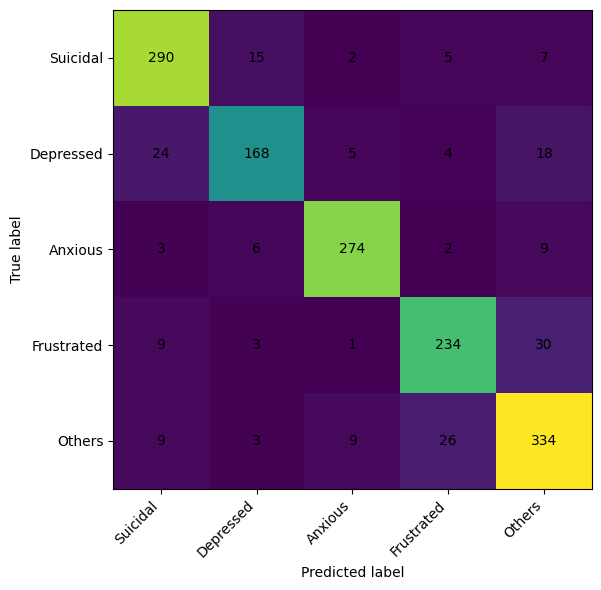

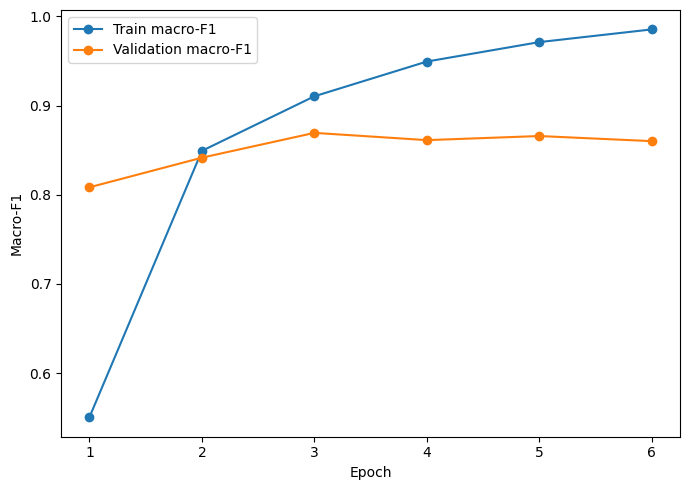

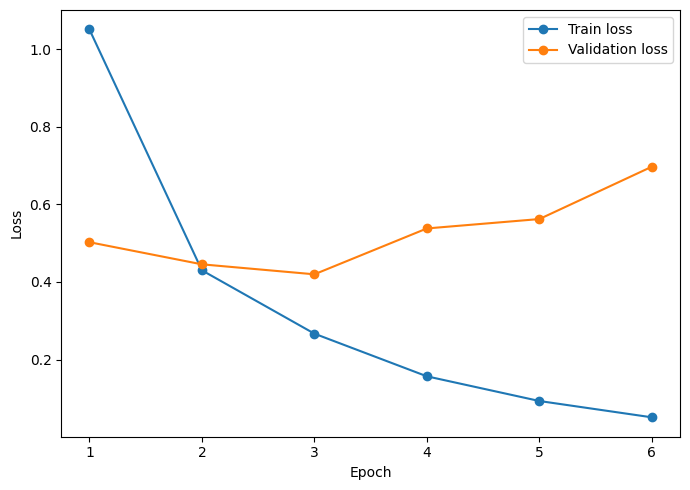

,seed,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,mcc,loss
0,13,0.872483,0.874291,0.865919,0.869344,0.872029,0.83927,0.419653


,precision,recall,f1-score,support
Suicidal,0.865672,0.909091,0.886850,319.000000
Depressed,0.861538,0.767123,0.811594,219.000000
Anxious,0.941581,0.931973,0.936752,294.000000
Frustrated,0.863469,0.844765,0.854015,277.000000
Others,0.839196,0.876640,0.857510,381.000000
accuracy,0.872483,0.872483,0.872483,0.872483
macro avg,0.874291,0.865919,0.869344,1490.000000
weighted avg,0.872863,0.872483,0.872029,1490.000000


,Suicidal,Depressed,Anxious,Frustrated,Others
Suicidal,290,15,2,5,7
Depressed,24,168,5,4,18
Anxious,3,6,274,2,9
Frustrated,9,3,1,234,30
Others,9,3,9,26,334


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

{
  "seed": 13,
  "run_id": "mentalroberta_full_seed13_len512_fea2991778f3",
  "model_zip": "/kaggle/working/mental_distress_step4/mentalroberta_full_seed13_len512_fea2991778f3_MODELS.zip",
  "model_zip_sha256": "ae62eda5cae606e041f77e2c9149a923336dea08dea8819f09594ca433b2d2d2",
  "artifact_zip": "/kaggle/working/mental_distress_step4/mentalroberta_full_seed13_len512_fea2991778f3_ARTIFACTS.zip",
  "artifact_zip_sha256": "23ceddd17dfe24eff0f1367824f8a020d83e606da643b295ab3927cc922d2603",
  "validation_macro_f1": 0.8693441437647778,
  "validation_accuracy": 0.87248322147651,
  "best_epoch": 3,
  "saved_model_predictions_exact_after_reload": true,
  "saved_model_logits_within_tolerance_after_reload": true,
  "saved_model_reload_logits_max_abs_diff": 0.0,
  "test_accessed": false,
  "status": "PASS"
}

>>> MentalRoBERTa principal seed 2/10: 42 <<<
{
  "starting_seed": 42,
  "run_id": "mentalroberta_full_seed42_len512_be72f916ca15",
  "model_key": "mentalroberta",
  "hf_authenticated": true

...

{"epoch": 3, "learning_rate": 1.3885350318471338e-05, "seed": 42, "train_loss": 0.2555736851060711, "train_macro_f1": 0.9133377893602942, "val_accuracy": 0.8664429530201342, "val_loss": 0.4381049190941673, "val_macro_f1": 0.8638036890725539}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{"epoch": 4, "learning_rate": 1.110828025477707e-05, "seed": 42, "train_loss": 0.1507859636743135, "train_macro_f1": 0.950487352088812, "val_accuracy": 0.8570469798657718, "val_loss": 0.557314766639681, "val_macro_f1": 0.8535282368052579}
{"epoch": 5, "learning_rate": 8.331210191082804e-06, "seed": 42, "train_loss": 0.0829147866642896, "train_macro_f1": 0.9743277603997328, "val_accuracy": 0.8617449664429531, "val_loss": 0.6243615323352634, "val_macro_f1": 0.8579798035685595}
{"epoch": 6, "learning_rate": 5.554140127388535e-06, "seed": 42, "train_loss": 0.044787434559864, "train_macro_f1": 0.9870279084335566, "val_accuracy": 0.8624161073825504, "val_loss": 0.7158095675170572, "val_macro_f1": 0.8588054857981889}


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

{
  "seed": 42,
  "best_epoch": 3,
  "validation": {
    "accuracy": 0.8664429530201342,
    "macro_precision": 0.8641035032963054,
    "macro_recall": 0.8636721656326645,
    "macro_f1": 0.8638036890725539,
    "weighted_f1": 0.8665456257224003,
    "mcc": 0.8317503315582748,
    "loss": 0.43810484437834496
  },
  "reproducibility": {
    "performed": false,
    "passed": null
  }
}


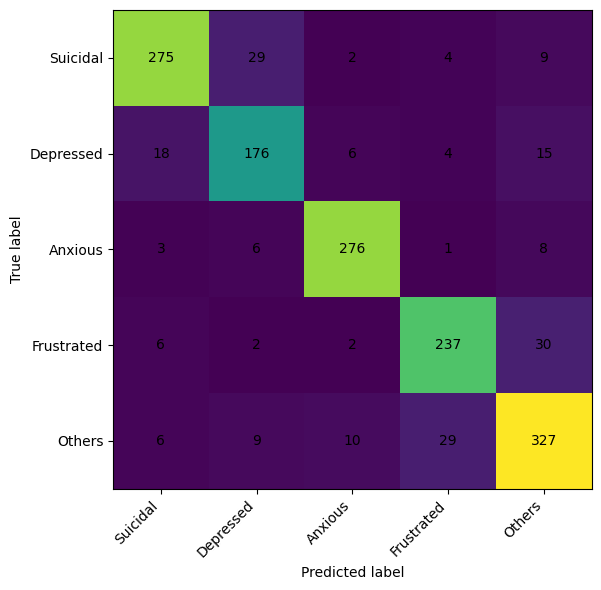

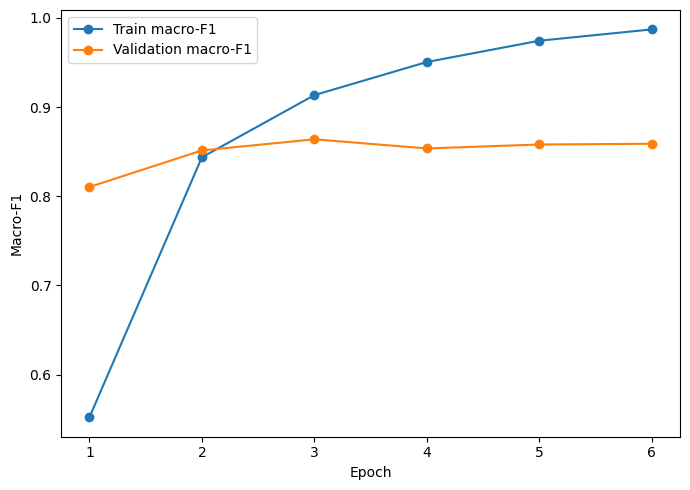

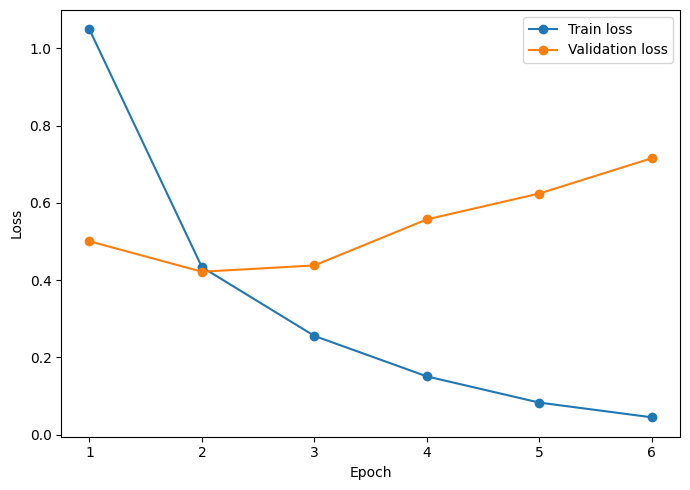

,seed,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,mcc,loss
0,42,0.866443,0.864104,0.863672,0.863804,0.866546,0.83175,0.438105


,precision,recall,f1-score,support
Suicidal,0.892857,0.862069,0.877193,319.000000
Depressed,0.792793,0.803653,0.798186,219.000000
Anxious,0.932432,0.938776,0.935593,294.000000
Frustrated,0.861818,0.855596,0.858696,277.000000
Others,0.840617,0.858268,0.849351,381.000000
accuracy,0.866443,0.866443,0.866443,0.866443
macro avg,0.864104,0.863672,0.863804,1490.000000
weighted avg,0.866830,0.866443,0.866546,1490.000000


,Suicidal,Depressed,Anxious,Frustrated,Others
Suicidal,275,29,2,4,9
Depressed,18,176,6,4,15
Anxious,3,6,276,1,8
Frustrated,6,2,2,237,30
Others,6,9,10,29,327


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

{
  "seed": 42,
  "run_id": "mentalroberta_full_seed42_len512_be72f916ca15",
  "model_zip": "/kaggle/working/mental_distress_step4/mentalroberta_full_seed42_len512_be72f916ca15_MODELS.zip",
  "model_zip_sha256": "6a91caab8c46baf504c8dd8c97b78af2c2417228f0bcd9598576585138e49ec2",
  "artifact_zip": "/kaggle/working/mental_distress_step4/mentalroberta_full_seed42_len512_be72f916ca15_ARTIFACTS.zip",
  "artifact_zip_sha256": "c45644bf88c9c813742de5613d7bd53c04c65d48f1b302824c618682d8744113",
  "validation_macro_f1": 0.8638036890725539,
  "validation_accuracy": 0.8664429530201342,
  "best_epoch": 3,
  "saved_model_predictions_exact_after_reload": true,
  "saved_model_logits_within_tolerance_after_reload": true,
  "saved_model_reload_logits_max_abs_diff": 0.0,
  "test_accessed": false,
  "status": "PASS"
}

>>> MentalRoBERTa principal seed 3/10: 77 <<<
{
  "starting_seed": 77,
  "run_id": "mentalroberta_full_seed77_len512_d14375990239",
  "model_key": "mentalroberta",
  "hf_authenticated": tr

...

{"epoch": 4, "learning_rate": 1.110828025477707e-05, "seed": 77, "train_loss": 0.16349924538956315, "train_macro_f1": 0.9487754882307307, "val_accuracy": 0.8590604026845637, "val_loss": 0.4916170203870775, "val_macro_f1": 0.8557094043558449}
{"epoch": 5, "learning_rate": 8.331210191082804e-06, "seed": 77, "train_loss": 0.09141639969887537, "train_macro_f1": 0.9739468233235348, "val_accuracy": 0.8691275167785235, "val_loss": 0.5732921267947144, "val_macro_f1": 0.8664756094088369}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{"epoch": 6, "learning_rate": 5.554140127388535e-06, "seed": 77, "train_loss": 0.04754670580253348, "train_macro_f1": 0.9871759314820542, "val_accuracy": 0.8664429530201342, "val_loss": 0.6859464262855933, "val_macro_f1": 0.8636595734055776}
{"epoch": 7, "learning_rate": 2.7770700636942676e-06, "seed": 77, "train_loss": 0.027986953909032643, "train_macro_f1": 0.9932384131927317, "val_accuracy": 0.8590604026845637, "val_loss": 0.7098067512073173, "val_macro_f1": 0.8566106387075857}
{"epoch": 8, "learning_rate": 0.0, "seed": 77, "train_loss": 0.01766183997921861, "train_macro_f1": 0.9959781425565855, "val_accuracy": 0.8651006711409396, "val_loss": 0.7339398504683323, "val_macro_f1": 0.8625825777690904}


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

{
  "seed": 77,
  "best_epoch": 5,
  "validation": {
    "accuracy": 0.8691275167785235,
    "macro_precision": 0.8665143089607706,
    "macro_recall": 0.8681289428346568,
    "macro_f1": 0.8664756094088369,
    "weighted_f1": 0.8684526737548652,
    "mcc": 0.8357935486327032,
    "loss": 0.5732921377830708
  },
  "reproducibility": {
    "performed": false,
    "passed": null
  }
}


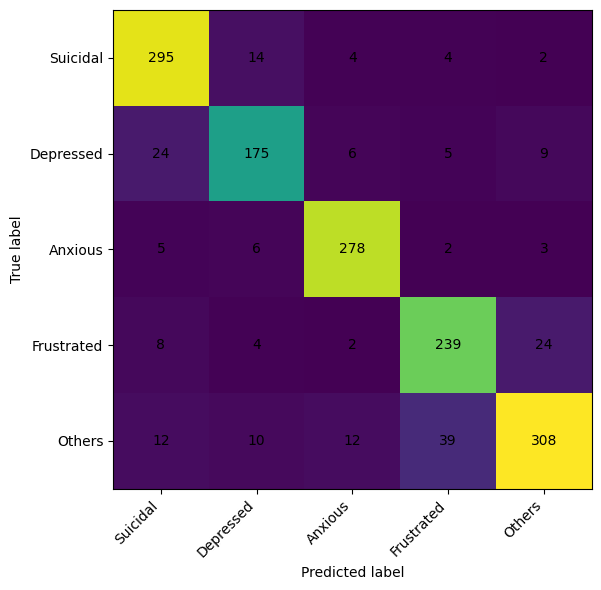

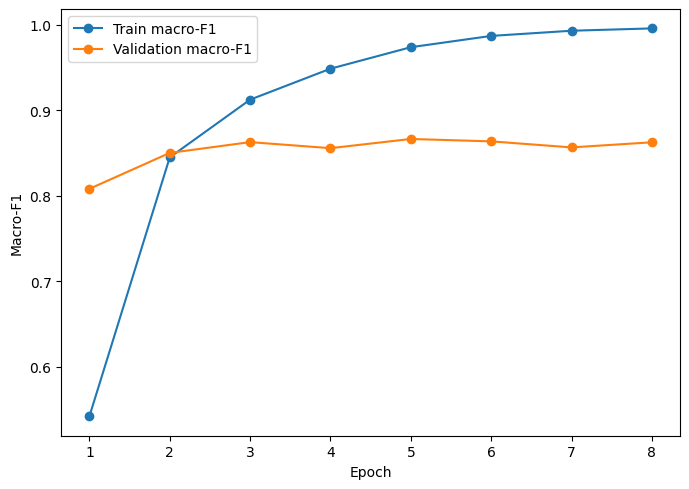

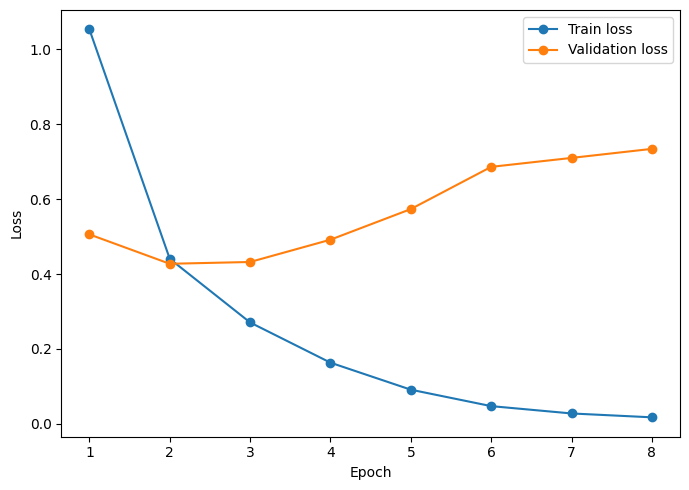

,seed,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,mcc,loss
0,77,0.869128,0.866514,0.868129,0.866476,0.868453,0.835794,0.573292


,precision,recall,f1-score,support
Suicidal,0.857558,0.924765,0.889894,319.000000
Depressed,0.837321,0.799087,0.817757,219.000000
Anxious,0.920530,0.945578,0.932886,294.000000
Frustrated,0.826990,0.862816,0.844523,277.000000
Others,0.890173,0.808399,0.847318,381.000000
accuracy,0.869128,0.869128,0.869128,0.869128
macro avg,0.866514,0.868129,0.866476,1490.000000
weighted avg,0.869666,0.869128,0.868453,1490.000000


,Suicidal,Depressed,Anxious,Frustrated,Others
Suicidal,295,14,4,4,2
Depressed,24,175,6,5,9
Anxious,5,6,278,2,3
Frustrated,8,4,2,239,24
Others,12,10,12,39,308


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

{
  "seed": 77,
  "run_id": "mentalroberta_full_seed77_len512_d14375990239",
  "model_zip": "/kaggle/working/mental_distress_step4/mentalroberta_full_seed77_len512_d14375990239_MODELS.zip",
  "model_zip_sha256": "f8d34a40229d1293924ef41d7f9e007fb85ac0747885db8a41b0190363bcf3d5",
  "artifact_zip": "/kaggle/working/mental_distress_step4/mentalroberta_full_seed77_len512_d14375990239_ARTIFACTS.zip",
  "artifact_zip_sha256": "6e3d4ae16d9cff4c4a94ba3964b4c16c434dbb4b4a3c90bb7142a327120d12c8",
  "validation_macro_f1": 0.8664756094088369,
  "validation_accuracy": 0.8691275167785235,
  "best_epoch": 5,
  "saved_model_predictions_exact_after_reload": true,
  "saved_model_logits_within_tolerance_after_reload": true,
  "saved_model_reload_logits_max_abs_diff": 0.0,
  "test_accessed": false,
  "status": "PASS"
}

>>> MentalRoBERTa principal seed 4/10: 123 <<<
{
  "starting_seed": 123,
  "run_id": "mentalroberta_full_seed123_len512_d1ad313ee75d",
  "model_key": "mentalroberta",
  "hf_authenticated":

...

{"epoch": 5, "learning_rate": 8.331210191082804e-06, "seed": 123, "train_loss": 0.08797274795683625, "train_macro_f1": 0.9731712960955807, "val_accuracy": 0.8530201342281879, "val_loss": 0.6309280721151939, "val_macro_f1": 0.8495704228894476}
{"epoch": 6, "learning_rate": 5.554140127388535e-06, "seed": 123, "train_loss": 0.05136528156945781, "train_macro_f1": 0.9838857288300339, "val_accuracy": 0.8570469798657718, "val_loss": 0.6790471679854501, "val_macro_f1": 0.8540140296205427}
{"epoch": 7, "learning_rate": 2.7770700636942676e-06, "seed": 123, "train_loss": 0.027706841958286536, "train_macro_f1": 0.9930564820383486, "val_accuracy": 0.8624161073825504, "val_loss": 0.7498825964783538, "val_macro_f1": 0.8595650517113078}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{"epoch": 8, "learning_rate": 0.0, "seed": 123, "train_loss": 0.016353861827562412, "train_macro_f1": 0.9965725963595984, "val_accuracy": 0.8624161073825504, "val_loss": 0.7662813047973764, "val_macro_f1": 0.8589434830299822}


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

{
  "seed": 123,
  "best_epoch": 7,
  "validation": {
    "accuracy": 0.8624161073825504,
    "macro_precision": 0.8599033505856578,
    "macro_recall": 0.8600729311861383,
    "macro_f1": 0.8595650517113078,
    "weighted_f1": 0.8618213015687652,
    "mcc": 0.8269045872806082,
    "loss": 0.7498825952820105
  },
  "reproducibility": {
    "performed": false,
    "passed": null
  }
}


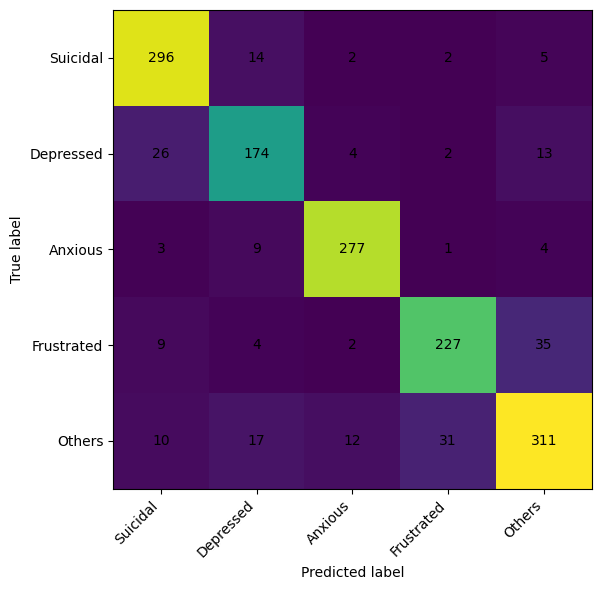

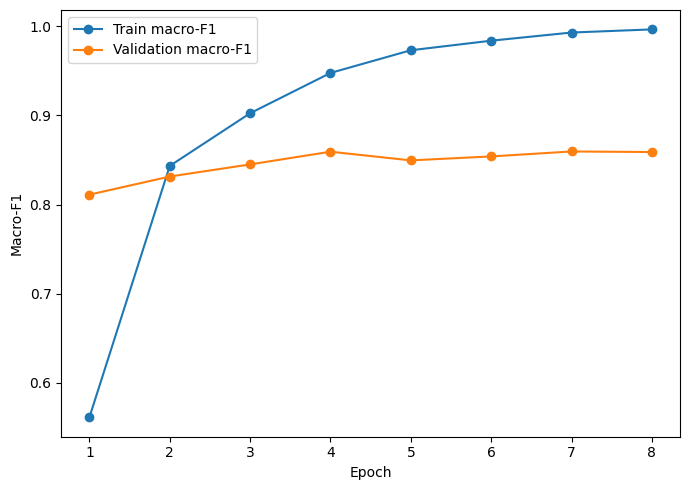

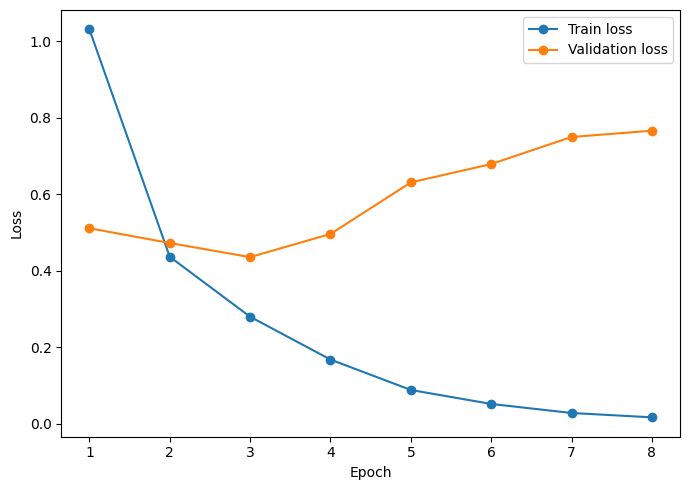

,seed,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,mcc,loss
0,123,0.862416,0.859903,0.860073,0.859565,0.861821,0.826905,0.749883


,precision,recall,f1-score,support
Suicidal,0.860465,0.927900,0.892911,319.000000
Depressed,0.798165,0.794521,0.796339,219.000000
Anxious,0.932660,0.942177,0.937394,294.000000
Frustrated,0.863118,0.819495,0.840741,277.000000
Others,0.845109,0.816273,0.830441,381.000000
accuracy,0.862416,0.862416,0.862416,0.862416
macro avg,0.859903,0.860073,0.859565,1490.000000
weighted avg,0.862120,0.862416,0.861821,1490.000000


,Suicidal,Depressed,Anxious,Frustrated,Others
Suicidal,296,14,2,2,5
Depressed,26,174,4,2,13
Anxious,3,9,277,1,4
Frustrated,9,4,2,227,35
Others,10,17,12,31,311


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

{
  "seed": 123,
  "run_id": "mentalroberta_full_seed123_len512_d1ad313ee75d",
  "model_zip": "/kaggle/working/mental_distress_step4/mentalroberta_full_seed123_len512_d1ad313ee75d_MODELS.zip",
  "model_zip_sha256": "dbacb698857d70d20bbbcbead873abc7c7226161ff983c477680c8726f99b487",
  "artifact_zip": "/kaggle/working/mental_distress_step4/mentalroberta_full_seed123_len512_d1ad313ee75d_ARTIFACTS.zip",
  "artifact_zip_sha256": "283b063df338d1ce50ca9dc60d49f027e91ae7cad024fe9b04e8200f9b3c8091",
  "validation_macro_f1": 0.8595650517113078,
  "validation_accuracy": 0.8624161073825504,
  "best_epoch": 7,
  "saved_model_predictions_exact_after_reload": true,
  "saved_model_logits_within_tolerance_after_reload": true,
  "saved_model_reload_logits_max_abs_diff": 0.0,
  "test_accessed": false,
  "status": "PASS"
}

>>> MentalRoBERTa principal seed 5/10: 211 <<<
{
  "starting_seed": 211,
  "run_id": "mentalroberta_full_seed211_len512_149308113b40",
  "model_key": "mentalroberta",
  "hf_authenticat

...

{"epoch": 4, "learning_rate": 1.110828025477707e-05, "seed": 211, "train_loss": 0.15505086935934473, "train_macro_f1": 0.9512779494425994, "val_accuracy": 0.8704697986577181, "val_loss": 0.5110667736513302, "val_macro_f1": 0.8654410249000369}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{"epoch": 5, "learning_rate": 8.331210191082804e-06, "seed": 211, "train_loss": 0.09329521238869755, "train_macro_f1": 0.973496074271614, "val_accuracy": 0.8651006711409396, "val_loss": 0.5602237649683859, "val_macro_f1": 0.8615831052100497}
{"epoch": 6, "learning_rate": 5.554140127388535e-06, "seed": 211, "train_loss": 0.0511360036890642, "train_macro_f1": 0.9861280904899198, "val_accuracy": 0.8651006711409396, "val_loss": 0.6992731816538503, "val_macro_f1": 0.8617761563284398}
{"epoch": 7, "learning_rate": 2.7770700636942676e-06, "seed": 211, "train_loss": 0.029666934396481253, "train_macro_f1": 0.992532700255891, "val_accuracy": 0.863758389261745, "val_loss": 0.7609525118432564, "val_macro_f1": 0.8599130072201835}


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

{
  "seed": 211,
  "best_epoch": 4,
  "validation": {
    "accuracy": 0.8704697986577181,
    "macro_precision": 0.8696231112908999,
    "macro_recall": 0.8635579058439161,
    "macro_f1": 0.8654410249000369,
    "weighted_f1": 0.8691691784626489,
    "mcc": 0.836959761959209,
    "loss": 0.5110667812369214
  },
  "reproducibility": {
    "performed": false,
    "passed": null
  }
}


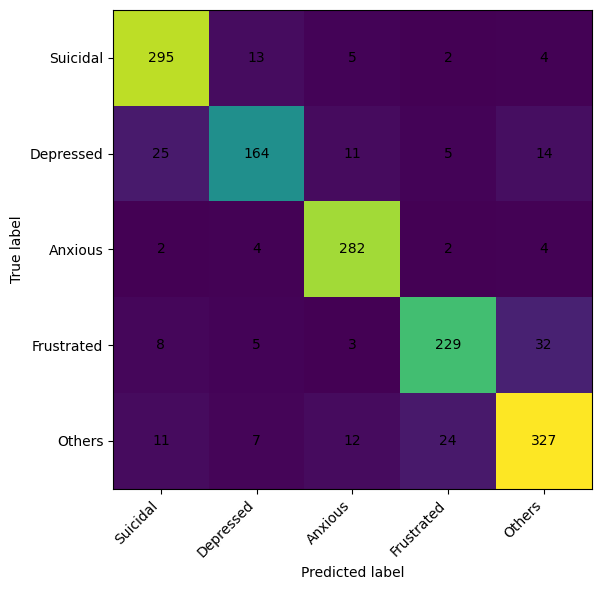

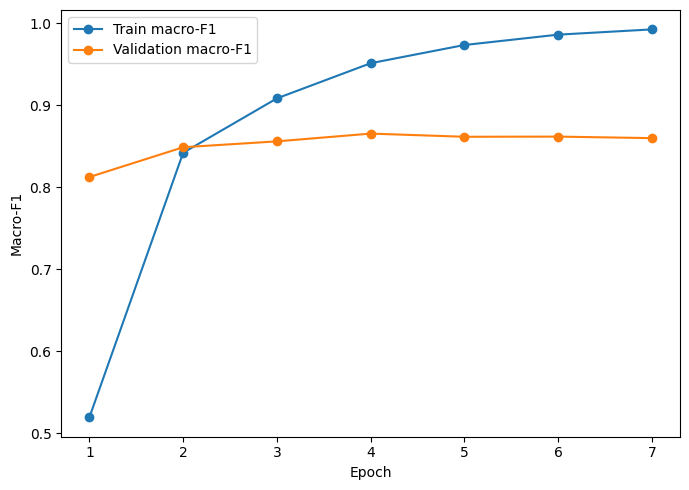

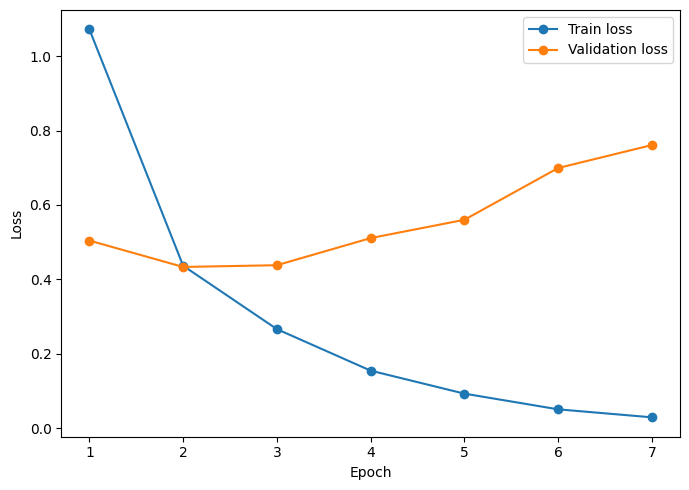

,seed,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,mcc,loss
0,211,0.87047,0.869623,0.863558,0.865441,0.869169,0.83696,0.511067


,precision,recall,f1-score,support
Suicidal,0.865103,0.924765,0.893939,319.00000
Depressed,0.849741,0.748858,0.796117,219.00000
Anxious,0.900958,0.959184,0.929160,294.00000
Frustrated,0.874046,0.826715,0.849722,277.00000
Others,0.858268,0.858268,0.858268,381.00000
accuracy,0.870470,0.870470,0.870470,0.87047
macro avg,0.869623,0.863558,0.865441,1490.00000
weighted avg,0.869835,0.870470,0.869169,1490.00000


,Suicidal,Depressed,Anxious,Frustrated,Others
Suicidal,295,13,5,2,4
Depressed,25,164,11,5,14
Anxious,2,4,282,2,4
Frustrated,8,5,3,229,32
Others,11,7,12,24,327


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

{
  "seed": 211,
  "run_id": "mentalroberta_full_seed211_len512_149308113b40",
  "model_zip": "/kaggle/working/mental_distress_step4/mentalroberta_full_seed211_len512_149308113b40_MODELS.zip",
  "model_zip_sha256": "b856d4ac2fbf4f0f383cf857706f3ce9163a0c9f4663595ce1f27068b76d5087",
  "artifact_zip": "/kaggle/working/mental_distress_step4/mentalroberta_full_seed211_len512_149308113b40_ARTIFACTS.zip",
  "artifact_zip_sha256": "56a312411d83f0325d2f6ad107f2c873c69133cd426b4f59b456cca1c365a76a",
  "validation_macro_f1": 0.8654410249000369,
  "validation_accuracy": 0.8704697986577181,
  "best_epoch": 4,
  "saved_model_predictions_exact_after_reload": true,
  "saved_model_logits_within_tolerance_after_reload": true,
  "saved_model_reload_logits_max_abs_diff": 0.0,
  "test_accessed": false,
  "status": "PASS"
}

>>> MentalRoBERTa principal seed 6/10: 340 <<<
{
  "starting_seed": 340,
  "run_id": "mentalroberta_full_seed340_len512_6353292c8230",
  "model_key": "mentalroberta",
  "hf_authenticat

...

{"epoch": 3, "learning_rate": 1.3885350318471338e-05, "seed": 340, "train_loss": 0.2688412160449521, "train_macro_f1": 0.9085657711458814, "val_accuracy": 0.8644295302013423, "val_loss": 0.4297811449174113, "val_macro_f1": 0.8627358279277855}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{"epoch": 4, "learning_rate": 1.110828025477707e-05, "seed": 340, "train_loss": 0.16222531281584146, "train_macro_f1": 0.9493986560342416, "val_accuracy": 0.863758389261745, "val_loss": 0.5061254407960496, "val_macro_f1": 0.8620575803872701}
{"epoch": 5, "learning_rate": 8.331210191082804e-06, "seed": 340, "train_loss": 0.0889989636339695, "train_macro_f1": 0.9746077539264743, "val_accuracy": 0.8651006711409396, "val_loss": 0.5832870502056141, "val_macro_f1": 0.861380652416228}
{"epoch": 6, "learning_rate": 5.554140127388535e-06, "seed": 340, "train_loss": 0.05282196567399464, "train_macro_f1": 0.984180934563773, "val_accuracy": 0.8644295302013423, "val_loss": 0.6358717483829319, "val_macro_f1": 0.8619653924958751}


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

{
  "seed": 340,
  "best_epoch": 3,
  "validation": {
    "accuracy": 0.8644295302013423,
    "macro_precision": 0.8663269367991588,
    "macro_recall": 0.8599818392711066,
    "macro_f1": 0.8627358279277855,
    "weighted_f1": 0.8646976806346393,
    "mcc": 0.8291473270566199,
    "loss": 0.4297811423972149
  },
  "reproducibility": {
    "performed": false,
    "passed": null
  }
}


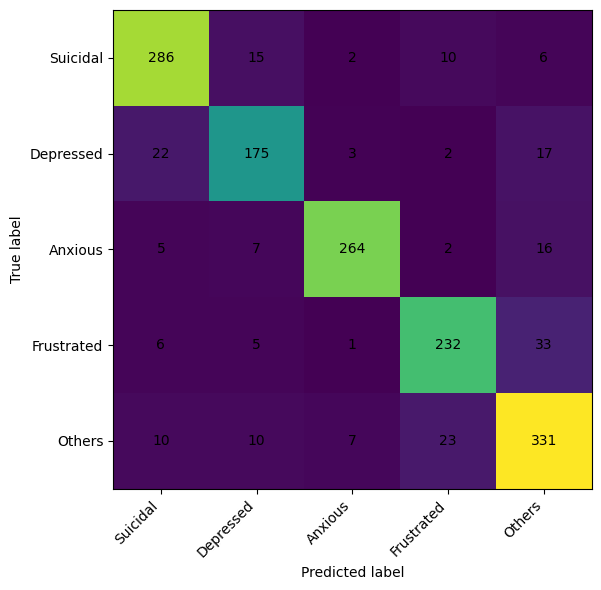

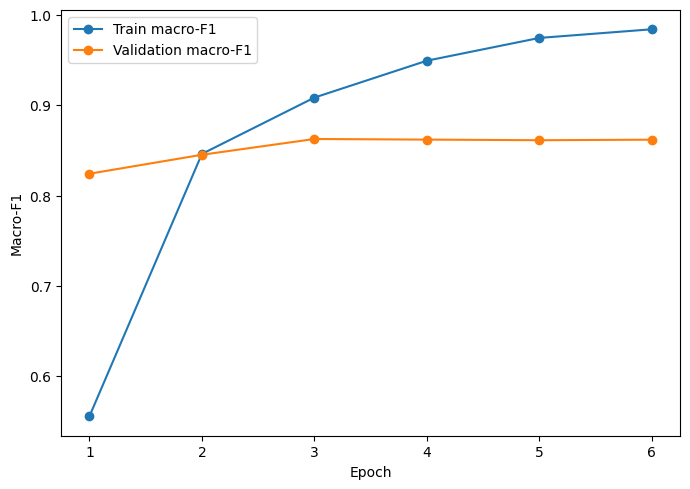

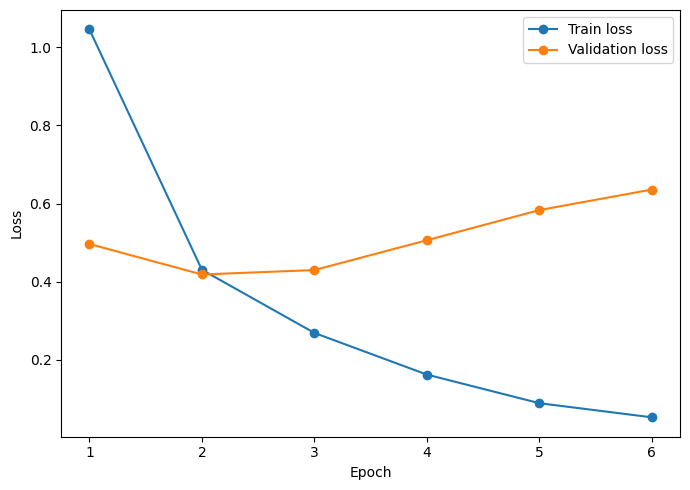

,seed,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,mcc,loss
0,340,0.86443,0.866327,0.859982,0.862736,0.864698,0.829147,0.429781


,precision,recall,f1-score,support
Suicidal,0.869301,0.896552,0.882716,319.00000
Depressed,0.825472,0.799087,0.812065,219.00000
Anxious,0.953069,0.897959,0.924694,294.00000
Frustrated,0.862454,0.837545,0.849817,277.00000
Others,0.821340,0.868766,0.844388,381.00000
accuracy,0.864430,0.864430,0.864430,0.86443
macro avg,0.866327,0.859982,0.862736,1490.00000
weighted avg,0.865851,0.864430,0.864698,1490.00000


,Suicidal,Depressed,Anxious,Frustrated,Others
Suicidal,286,15,2,10,6
Depressed,22,175,3,2,17
Anxious,5,7,264,2,16
Frustrated,6,5,1,232,33
Others,10,10,7,23,331


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

{
  "seed": 340,
  "run_id": "mentalroberta_full_seed340_len512_6353292c8230",
  "model_zip": "/kaggle/working/mental_distress_step4/mentalroberta_full_seed340_len512_6353292c8230_MODELS.zip",
  "model_zip_sha256": "ac5c78e3fb9cdb420871ab00786b4290521dfbbbbb7cc05e82b03367e16d1806",
  "artifact_zip": "/kaggle/working/mental_distress_step4/mentalroberta_full_seed340_len512_6353292c8230_ARTIFACTS.zip",
  "artifact_zip_sha256": "fff4222a9a65067fcd8e3a8c0944e63437d9acd55e353c838a507eab1d5183e1",
  "validation_macro_f1": 0.8627358279277855,
  "validation_accuracy": 0.8644295302013423,
  "best_epoch": 3,
  "saved_model_predictions_exact_after_reload": true,
  "saved_model_logits_within_tolerance_after_reload": true,
  "saved_model_reload_logits_max_abs_diff": 0.0,
  "test_accessed": false,
  "status": "PASS"
}

>>> MentalRoBERTa principal seed 7/10: 512 <<<
{
  "starting_seed": 512,
  "run_id": "mentalroberta_full_seed512_len512_412e1caa7392",
  "model_key": "mentalroberta",
  "hf_authenticat

...

{"epoch": 6, "learning_rate": 5.554140127388535e-06, "seed": 512, "train_loss": 0.050508744761547056, "train_macro_f1": 0.9854732596266826, "val_accuracy": 0.8664429530201342, "val_loss": 0.651294331783085, "val_macro_f1": 0.8633010448962868}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{"epoch": 7, "learning_rate": 2.7770700636942676e-06, "seed": 512, "train_loss": 0.025770254454047542, "train_macro_f1": 0.9926686763168503, "val_accuracy": 0.8630872483221477, "val_loss": 0.7251281626008439, "val_macro_f1": 0.8591246236724149}
{"epoch": 8, "learning_rate": 0.0, "seed": 512, "train_loss": 0.01580393964412408, "train_macro_f1": 0.9959676015638991, "val_accuracy": 0.8630872483221477, "val_loss": 0.7500303103670559, "val_macro_f1": 0.858912066036531}


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

{
  "seed": 512,
  "best_epoch": 6,
  "validation": {
    "accuracy": 0.8664429530201342,
    "macro_precision": 0.862724273315855,
    "macro_recall": 0.8641744276863828,
    "macro_f1": 0.8633010448962868,
    "weighted_f1": 0.8661360735334699,
    "mcc": 0.8319036792726389,
    "loss": 0.6512943482106152
  },
  "reproducibility": {
    "performed": false,
    "passed": null
  }
}


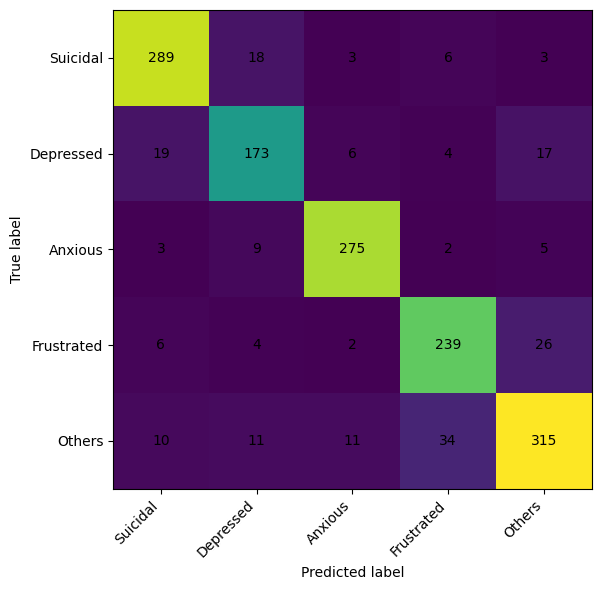

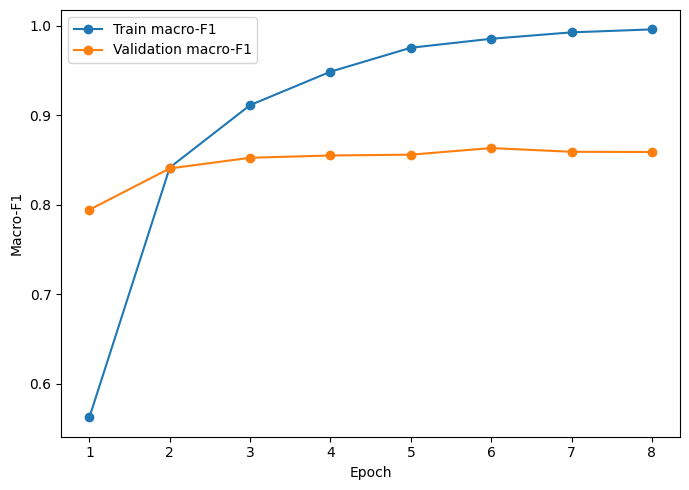

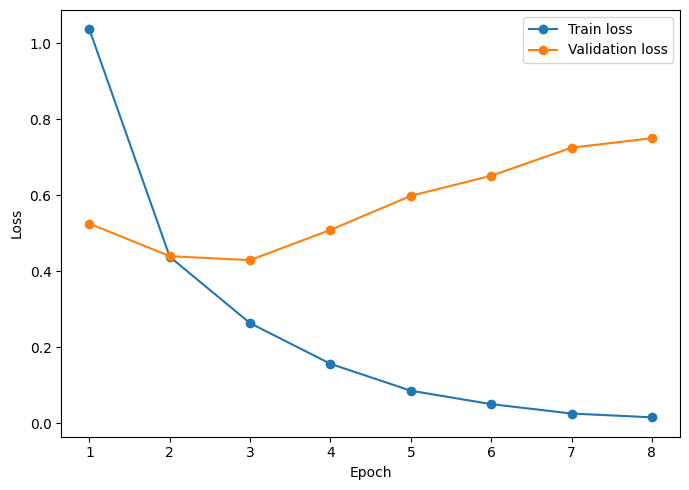

,seed,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,mcc,loss
0,512,0.866443,0.862724,0.864174,0.863301,0.866136,0.831904,0.651294


,precision,recall,f1-score,support
Suicidal,0.883792,0.905956,0.894737,319.000000
Depressed,0.804651,0.789954,0.797235,219.000000
Anxious,0.925926,0.935374,0.930626,294.000000
Frustrated,0.838596,0.862816,0.850534,277.000000
Others,0.860656,0.826772,0.843373,381.000000
accuracy,0.866443,0.866443,0.866443,0.866443
macro avg,0.862724,0.864174,0.863301,1490.000000
weighted avg,0.866155,0.866443,0.866136,1490.000000


,Suicidal,Depressed,Anxious,Frustrated,Others
Suicidal,289,18,3,6,3
Depressed,19,173,6,4,17
Anxious,3,9,275,2,5
Frustrated,6,4,2,239,26
Others,10,11,11,34,315


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

{
  "seed": 512,
  "run_id": "mentalroberta_full_seed512_len512_412e1caa7392",
  "model_zip": "/kaggle/working/mental_distress_step4/mentalroberta_full_seed512_len512_412e1caa7392_MODELS.zip",
  "model_zip_sha256": "fcde3357bb07c443d38482129e3e339b28fd6ba6f8a552dc6f6ac9e1f5f97f0b",
  "artifact_zip": "/kaggle/working/mental_distress_step4/mentalroberta_full_seed512_len512_412e1caa7392_ARTIFACTS.zip",
  "artifact_zip_sha256": "9db1ec1a67952c3868160ed365b03052839ac936c1d99658017540357e448c0c",
  "validation_macro_f1": 0.8633010448962868,
  "validation_accuracy": 0.8664429530201342,
  "best_epoch": 6,
  "saved_model_predictions_exact_after_reload": true,
  "saved_model_logits_within_tolerance_after_reload": true,
  "saved_model_reload_logits_max_abs_diff": 0.0,
  "test_accessed": false,
  "status": "PASS"
}

>>> MentalRoBERTa principal seed 8/10: 1024 <<<
{
  "starting_seed": 1024,
  "run_id": "mentalroberta_full_seed1024_len512_e91f034d8a71",
  "model_key": "mentalroberta",
  "hf_authenti

...

{"epoch": 5, "learning_rate": 8.331210191082804e-06, "seed": 1024, "train_loss": 0.09395017027937953, "train_macro_f1": 0.971614040578712, "val_accuracy": 0.8671140939597315, "val_loss": 0.603165548177586, "val_macro_f1": 0.8638844215679609}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{"epoch": 6, "learning_rate": 5.554140127388535e-06, "seed": 1024, "train_loss": 0.05368521896924589, "train_macro_f1": 0.9849159484255964, "val_accuracy": 0.8610738255033556, "val_loss": 0.6800009757194405, "val_macro_f1": 0.8570173793219185}
{"epoch": 7, "learning_rate": 2.7770700636942676e-06, "seed": 1024, "train_loss": 0.02741849329114991, "train_macro_f1": 0.9930065089103831, "val_accuracy": 0.8610738255033556, "val_loss": 0.756863968157297, "val_macro_f1": 0.8576116012341336}
{"epoch": 8, "learning_rate": 0.0, "seed": 1024, "train_loss": 0.01524598451814999, "train_macro_f1": 0.9961390935359798, "val_accuracy": 0.8610738255033556, "val_loss": 0.7522589604056209, "val_macro_f1": 0.8576837489251263}


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

{
  "seed": 1024,
  "best_epoch": 5,
  "validation": {
    "accuracy": 0.8671140939597315,
    "macro_precision": 0.8687934552484855,
    "macro_recall": 0.8616055116745338,
    "macro_f1": 0.8638844215679609,
    "weighted_f1": 0.8662395416666986,
    "mcc": 0.8329168962483758,
    "loss": 0.6031655855780005
  },
  "reproducibility": {
    "performed": false,
    "passed": null
  }
}


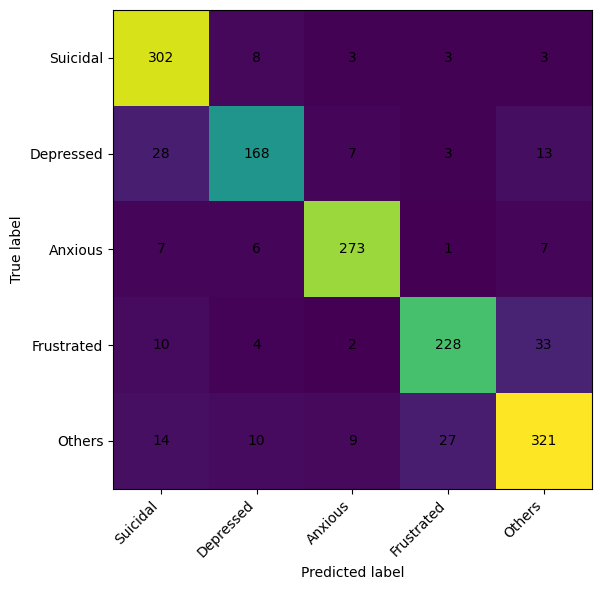

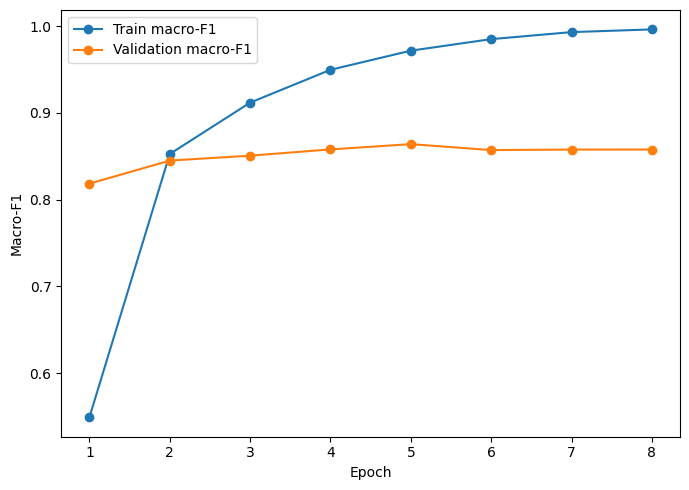

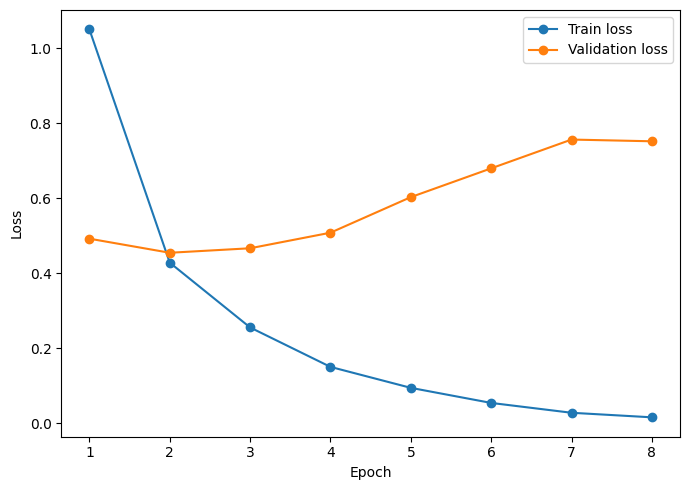

,seed,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,mcc,loss
0,1024,0.867114,0.868793,0.861606,0.863884,0.86624,0.832917,0.603166


,precision,recall,f1-score,support
Suicidal,0.836565,0.946708,0.888235,319.000000
Depressed,0.857143,0.767123,0.809639,219.000000
Anxious,0.928571,0.928571,0.928571,294.000000
Frustrated,0.870229,0.823105,0.846011,277.000000
Others,0.851459,0.842520,0.846966,381.000000
accuracy,0.867114,0.867114,0.867114,0.867114
macro avg,0.868793,0.861606,0.863884,1490.000000
weighted avg,0.867811,0.867114,0.866240,1490.000000


,Suicidal,Depressed,Anxious,Frustrated,Others
Suicidal,302,8,3,3,3
Depressed,28,168,7,3,13
Anxious,7,6,273,1,7
Frustrated,10,4,2,228,33
Others,14,10,9,27,321


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

{
  "seed": 1024,
  "run_id": "mentalroberta_full_seed1024_len512_e91f034d8a71",
  "model_zip": "/kaggle/working/mental_distress_step4/mentalroberta_full_seed1024_len512_e91f034d8a71_MODELS.zip",
  "model_zip_sha256": "eb93ce4dc3178b77765cff978f93d4d5d0ca697fa444e7982975d021b1fd169a",
  "artifact_zip": "/kaggle/working/mental_distress_step4/mentalroberta_full_seed1024_len512_e91f034d8a71_ARTIFACTS.zip",
  "artifact_zip_sha256": "4ebc235f48f1b990bfff860f758729510de544b724da836a541bd1067e4426df",
  "validation_macro_f1": 0.8638844215679609,
  "validation_accuracy": 0.8671140939597315,
  "best_epoch": 5,
  "saved_model_predictions_exact_after_reload": true,
  "saved_model_logits_within_tolerance_after_reload": true,
  "saved_model_reload_logits_max_abs_diff": 0.0,
  "test_accessed": false,
  "status": "PASS"
}

>>> MentalRoBERTa principal seed 9/10: 2026 <<<
{
  "starting_seed": 2026,
  "run_id": "mentalroberta_full_seed2026_len512_f6630d942394",
  "model_key": "mentalroberta",
  "hf_auth

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{"epoch": 7, "learning_rate": 2.7770700636942676e-06, "seed": 2026, "train_loss": 0.027209442075254085, "train_macro_f1": 0.9930908954240895, "val_accuracy": 0.859731543624161, "val_loss": 0.7723627045492786, "val_macro_f1": 0.8561889071076635}
{"epoch": 8, "learning_rate": 0.0, "seed": 2026, "train_loss": 0.019785033760083153, "train_macro_f1": 0.9956063593869571, "val_accuracy": 0.863758389261745, "val_loss": 0.7744030748804931, "val_macro_f1": 0.860510673802524}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

{
  "seed": 2026,
  "best_epoch": 8,
  "validation": {
    "accuracy": 0.863758389261745,
    "macro_precision": 0.8612007441443061,
    "macro_recall": 0.8605654002466208,
    "macro_f1": 0.860510673802524,
    "weighted_f1": 0.8632192321463585,
    "mcc": 0.8285419855721832,
    "loss": 0.7744033230185796
  },
  "reproducibility": {
    "performed": false,
    "passed": null
  }
}


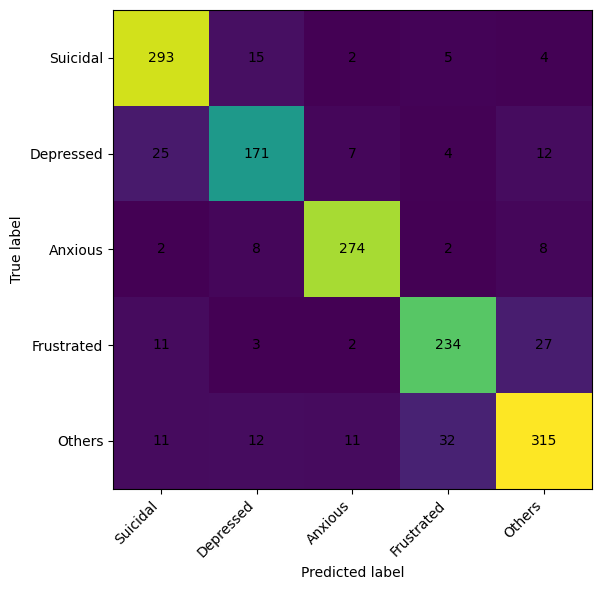

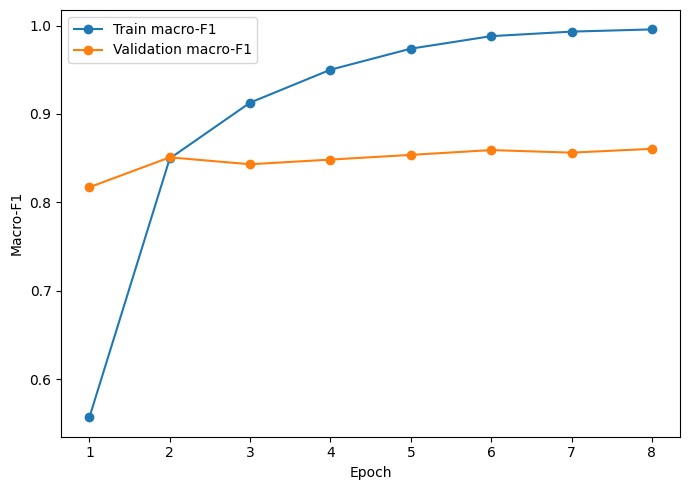

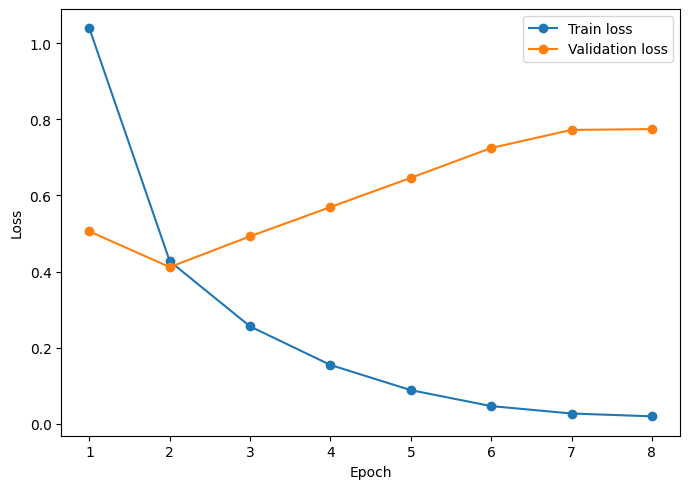

,seed,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,mcc,loss
0,2026,0.863758,0.861201,0.860565,0.860511,0.863219,0.828542,0.774403


,precision,recall,f1-score,support
Suicidal,0.856725,0.918495,0.886536,319.000000
Depressed,0.818182,0.780822,0.799065,219.000000
Anxious,0.925676,0.931973,0.928814,294.000000
Frustrated,0.844765,0.844765,0.844765,277.000000
Others,0.860656,0.826772,0.843373,381.000000
accuracy,0.863758,0.863758,0.863758,0.863758
macro avg,0.861201,0.860565,0.860511,1490.000000
weighted avg,0.863447,0.863758,0.863219,1490.000000


,Suicidal,Depressed,Anxious,Frustrated,Others
Suicidal,293,15,2,5,4
Depressed,25,171,7,4,12
Anxious,2,8,274,2,8
Frustrated,11,3,2,234,27
Others,11,12,11,32,315


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

{
  "seed": 2026,
  "run_id": "mentalroberta_full_seed2026_len512_f6630d942394",
  "model_zip": "/kaggle/working/mental_distress_step4/mentalroberta_full_seed2026_len512_f6630d942394_MODELS.zip",
  "model_zip_sha256": "499b82831bd91eeab5964ce347d09bab39359080cf26477e60ee23a3436ae2d8",
  "artifact_zip": "/kaggle/working/mental_distress_step4/mentalroberta_full_seed2026_len512_f6630d942394_ARTIFACTS.zip",
  "artifact_zip_sha256": "4d07884013a0f5af78f724e33e95a4ebe681a7856e4059aad4ea1ee309f906d7",
  "validation_macro_f1": 0.860510673802524,
  "validation_accuracy": 0.863758389261745,
  "best_epoch": 8,
  "saved_model_predictions_exact_after_reload": true,
  "saved_model_logits_within_tolerance_after_reload": true,
  "saved_model_reload_logits_max_abs_diff": 0.0,
  "test_accessed": false,
  "status": "PASS"
}

>>> MentalRoBERTa principal seed 10/10: 3407 <<<
{
  "starting_seed": 3407,
  "run_id": "mentalroberta_full_seed3407_len512_d8596ea710c3",
  "model_key": "mentalroberta",
  "hf_authe

...

{"epoch": 4, "learning_rate": 1.110828025477707e-05, "seed": 3407, "train_loss": 0.14410056258335618, "train_macro_f1": 0.9528546428167809, "val_accuracy": 0.8550335570469799, "val_loss": 0.5599714076033975, "val_macro_f1": 0.8481498818527526}
{"epoch": 5, "learning_rate": 8.331210191082804e-06, "seed": 3407, "train_loss": 0.07445162597592081, "train_macro_f1": 0.9790658235639939, "val_accuracy": 0.8543624161073825, "val_loss": 0.6403174043514285, "val_macro_f1": 0.8490795229059709}
{"epoch": 6, "learning_rate": 5.554140127388535e-06, "seed": 3407, "train_loss": 0.04369439905021058, "train_macro_f1": 0.9873958712512481, "val_accuracy": 0.8630872483221477, "val_loss": 0.7434695098325673, "val_macro_f1": 0.85691694467924}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{"epoch": 7, "learning_rate": 2.7770700636942676e-06, "seed": 3407, "train_loss": 0.022733560591137375, "train_macro_f1": 0.993774744570889, "val_accuracy": 0.8590604026845637, "val_loss": 0.790540110345011, "val_macro_f1": 0.8544199643936146}
{"epoch": 8, "learning_rate": 0.0, "seed": 3407, "train_loss": 0.010860245778641336, "train_macro_f1": 0.9976440616887239, "val_accuracy": 0.8604026845637583, "val_loss": 0.7952569029287704, "val_macro_f1": 0.8557079841029303}


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

{
  "seed": 3407,
  "best_epoch": 6,
  "validation": {
    "accuracy": 0.8630872483221477,
    "macro_precision": 0.8631934085738788,
    "macro_recall": 0.854547487656431,
    "macro_f1": 0.85691694467924,
    "weighted_f1": 0.8611579889489596,
    "mcc": 0.8277346414756822,
    "loss": 0.7434694589748541
  },
  "reproducibility": {
    "performed": false,
    "passed": null
  }
}


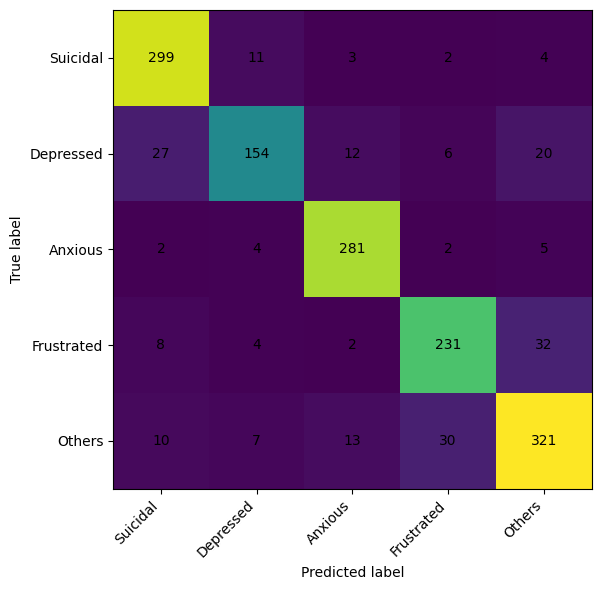

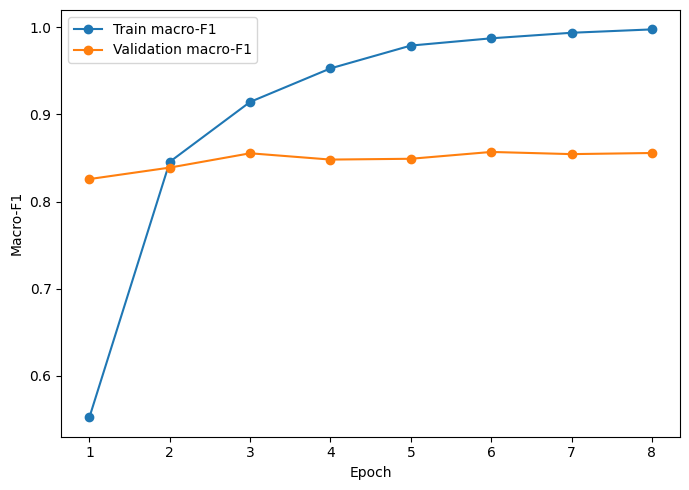

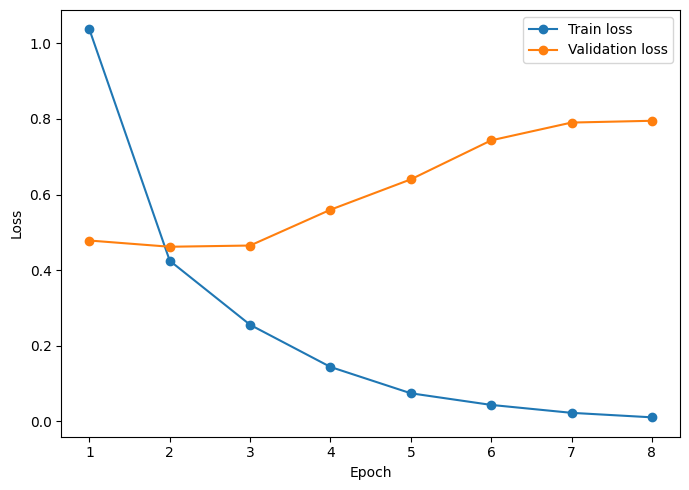

,seed,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,mcc,loss
0,3407,0.863087,0.863193,0.854547,0.856917,0.861158,0.827735,0.743469


,precision,recall,f1-score,support
Suicidal,0.864162,0.937304,0.899248,319.000000
Depressed,0.855556,0.703196,0.771930,219.000000
Anxious,0.903537,0.955782,0.928926,294.000000
Frustrated,0.852399,0.833935,0.843066,277.000000
Others,0.840314,0.842520,0.841415,381.000000
accuracy,0.863087,0.863087,0.863087,0.863087
macro avg,0.863193,0.854547,0.856917,1490.000000
weighted avg,0.862381,0.863087,0.861158,1490.000000


,Suicidal,Depressed,Anxious,Frustrated,Others
Suicidal,299,11,3,2,4
Depressed,27,154,12,6,20
Anxious,2,4,281,2,5
Frustrated,8,4,2,231,32
Others,10,7,13,30,321


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

{
  "seed": 3407,
  "run_id": "mentalroberta_full_seed3407_len512_d8596ea710c3",
  "model_zip": "/kaggle/working/mental_distress_step4/mentalroberta_full_seed3407_len512_d8596ea710c3_MODELS.zip",
  "model_zip_sha256": "cd2bda7acfd24853f81a64db2249dd6a7b0abbf8f4d5b8c5dc6d0ece02df0ec0",
  "artifact_zip": "/kaggle/working/mental_distress_step4/mentalroberta_full_seed3407_len512_d8596ea710c3_ARTIFACTS.zip",
  "artifact_zip_sha256": "e8d96433959e8113700e980a8d31c03bd4ee1ea16ddb95232b299d5bfbd978e8",
  "validation_macro_f1": 0.85691694467924,
  "validation_accuracy": 0.8630872483221477,
  "best_epoch": 6,
  "saved_model_predictions_exact_after_reload": true,
  "saved_model_logits_within_tolerance_after_reload": true,
  "saved_model_reload_logits_max_abs_diff": 0.0,
  "test_accessed": false,
  "status": "PASS"
}


,seed,validation_macro_f1,validation_accuracy,best_epoch,status
0,13,0.869344,0.872483,3,PASS
1,42,0.863804,0.866443,3,PASS
2,77,0.866476,0.869128,5,PASS
3,123,0.859565,0.862416,7,PASS
4,211,0.865441,0.870470,4,PASS
5,340,0.862736,0.864430,3,PASS
6,512,0.863301,0.866443,6,PASS
7,1024,0.863884,0.867114,5,PASS
8,2026,0.860511,0.863758,8,PASS
9,3407,0.856917,0.863087,6,PASS


{
  "model_key": "mentalroberta",
  "model_source": "mental/mental-roberta-base",
  "model_revision": "610e9d35d8f2550d713579077242d5e523209cea",
  "seeds": [
    13,
    42,
    77,
    123,
    211,
    340,
    512,
    1024,
    2026,
    3407
  ],
  "max_length": 512,
  "train_batch_size": 8,
  "eval_batch_size": 16,
  "grad_accum_steps": 4,
  "epochs": 8,
  "patience": 3,
  "learning_rate": 2e-05,
  "weight_decay": 0.01,
  "warmup_ratio": 0.1,
  "max_grad_norm": 1.0,
  "run_mode": "full",
  "data_sha256": {
    "train": "1bac0d2f4e0f4d3da940b08a21bd3c6e18b1d958c57cb263c89a900381572d5b",
    "validation": "88835cd714b02efbd230536c7de3f455e807051a23a1786640b0e8b26b430165"
  },
  "validation_macro_f1_mean": 0.8631978431731311,
  "validation_macro_f1_sample_sd": 0.003566556282862149,
  "validation_accuracy_mean": 0.8665771812080537,
  "completed_seeds": 10,
  "all_status_pass": true,
  "test_accessed": false
}


In [9]:
all_seed_status = []
for seed_index, seed in enumerate(SEEDS, start=1):
    print(f"\n>>> MentalRoBERTa principal seed {seed_index}/{len(SEEDS)}: {seed} <<<")
    status = run_seed(seed)
    all_seed_status.append(status)

summary_df = pd.DataFrame(all_seed_status).sort_values("seed").reset_index(drop=True)
summary_csv = root / f"{MODEL_KEY}_{RUN_MODE}_10seed_summary.csv"
summary_json = root / f"{MODEL_KEY}_{RUN_MODE}_10seed_summary.json"
summary_df.to_csv(summary_csv, index=False, float_format="%.17g")

summary_payload = {
    "model_key": MODEL_KEY,
    "model_source": model_source,
    "model_revision": resolved_revision,
    "seeds": SEEDS,
    "max_length": MAX_LENGTH,
    "train_batch_size": TRAIN_BATCH_SIZE,
    "eval_batch_size": EVAL_BATCH_SIZE,
    "grad_accum_steps": GRAD_ACCUM_STEPS,
    "epochs": EPOCHS if RUN_MODE == "full" else SMOKE_EPOCHS,
    "patience": PATIENCE,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "warmup_ratio": WARMUP_RATIO,
    "max_grad_norm": MAX_GRAD_NORM,
    "run_mode": RUN_MODE,
    "data_sha256": integrity["sha256"],
    "validation_macro_f1_mean": float(summary_df["validation_macro_f1"].mean()),
    "validation_macro_f1_sample_sd": float(summary_df["validation_macro_f1"].std(ddof=1)),
    "validation_accuracy_mean": float(summary_df["validation_accuracy"].mean()),
    "completed_seeds": int(len(summary_df)),
    "all_status_pass": bool(summary_df["status"].eq("PASS").all()),
    "test_accessed": False,
}
with summary_json.open("w", encoding="utf-8") as f:
    json.dump(summary_payload, f, indent=2, sort_keys=True)

display(summary_df[["seed", "validation_macro_f1", "validation_accuracy", "best_epoch", "status"]])
print(json.dumps(summary_payload, indent=2))
assert len(summary_df) == len(SEEDS)
assert summary_df["status"].eq("PASS").all()
assert summary_df["test_accessed"].eq(False).all()
